#### Processing mORF ONT data, include QC and dedup

#### We will matching the adaptor for each of six samples and trim them using edlib - similar to what lima does - test using first 1k reads

#### Only three samples (bc04-06) containing UMIs were further leveraged for Benchmarking


- original barcodes
#### Define the adaptors
adaptors_5p = {
    "bc01": "CTACACGACGCTCTTCCGATCTACTACACGCAATGAAGTCGCAGGGTTGG",
    "bc02": "CTACACGACGCTCTTCCGATCTACTAGTAGCAATGAAGTCGCAGGGTTGG",
    "bc03": "CTACACGACGCTCTTCCGATCTAGTGTACGCAATGAAGTCGCAGGGTTGG",
    "bc04": "CTACACGACGCTCTTCCGATCTATCACTAGCAATGAAGTCGCAGGGTTGG",
    "bc05": "CTACACGACGCTCTTCCGATCTCAGCTGTGCAATGAAGTCGCAGGGTTGG",
    "bc06": "CTACACGACGCTCTTCCGATCTCAGTCACGCAATGAAGTCGCAGGGTTGG"
}
adaptor_3p = "CTCTGCGTTGATACCACTGCTT"

In [ ]:
import os
import shutil
import gzip
import multiprocessing
from Bio import SeqIO
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
import Levenshtein

# Define the adaptors
adaptors_5p = {
    "bc01": "ACTACACGCA",
    "bc02": "ACTAGTAGCA",
    "bc03": "AGTGTACGCA",
    "bc04": "ATCACTAGCA",
    "bc05": "CAGCTGTGCA",
    "bc06": "CAGTCACGCA"
}
adaptor_3p = "CTCTGCGTTGAT"

# Function to find exact match adaptor within the sequence
def find_exact_adaptor(seq, adaptor, offset=0):
    pos = seq.find(adaptor)
    if pos != -1:
        return pos + offset, pos + len(adaptor) + offset
    return None

# Function to find adaptor within the sequence allowing for 1 edit distance
def find_adaptor_with_edit_distance(seq, adaptor, max_distance=1, offset=0):
    for i in range(len(seq) - len(adaptor) + 1):
        subseq = seq[i:i + len(adaptor)]
        if Levenshtein.distance(subseq, adaptor) <= max_distance:
            return i + offset, i + len(adaptor) + offset
    return None

# Function to process a single read
def process_read(record, adaptor_positions, window_size):
    def search_adaptors(seq, seq_type):
        # Check for 3' adaptor (non-RC) at the end within the specified window size
        loc_3p = find_exact_adaptor(seq[-window_size:], adaptor_3p, offset=len(seq) - window_size)
        if not loc_3p:
            loc_3p = find_adaptor_with_edit_distance(seq[-window_size:], adaptor_3p, offset=len(seq) - window_size)
        if loc_3p:
            # Adjust positions to be relative to the last window_size bp
            relative_3p_start = loc_3p[0] - (len(seq) - window_size)
            relative_3p_end = loc_3p[1] - (len(seq) - window_size)
            adaptor_positions['3p_start'].append(relative_3p_start)
            adaptor_positions['3p_end'].append(relative_3p_end)
            for bc_name, adaptor_5p in adaptors_5p.items():
                # Check for 5' adaptor within the first window_size bp
                loc_5p = find_exact_adaptor(seq[:window_size], adaptor_5p)
                if loc_5p:
                    adaptor_positions['5p_start'].append(loc_5p[0])
                    adaptor_positions['5p_end'].append(loc_5p[1])
                    # Trim 18 bases after the 5' adaptor sequence
                    trimmed_seq = seq[loc_5p[1] + 18:loc_3p[0]]
                    return bc_name, trimmed_seq, True
            return None, None, True  # If 3' adaptor is found but 5' adaptor is not found, stop further processing
        return None, None, False

    # Search in original sequence
    bc_name, trimmed_seq, found_3p = search_adaptors(str(record.seq), "original")
    if bc_name and trimmed_seq:
        return bc_name, trimmed_seq

    # Only search in reverse complement sequence if 3' adaptor is not found in original sequence
    if not found_3p:
        reverse_complement_seq = str(record.seq.reverse_complement())
        bc_name, trimmed_seq, _ = search_adaptors(reverse_complement_seq, "reverse complement")
        if bc_name and trimmed_seq:
            return bc_name, trimmed_seq

    return None, None

def process_chunk(chunk_file, output_dir, window_size):
    output_files = {bc: open(os.path.join(output_dir, f"{os.path.basename(chunk_file)}_{bc}_{window_size}bp.fasta"), "w") for bc in adaptors_5p}
    adaptor_positions = {'3p_start': [], '3p_end': [], '5p_start': [], '5p_end': []}

    records = list(SeqIO.parse(chunk_file, "fastq"))  # Process all reads in the chunk file
    results = [process_read(record, adaptor_positions, window_size) for record in records]

    for record, result in zip(records, results):
        bc_name, trimmed_seq = result
        if bc_name and trimmed_seq:
            trimmed_record = SeqRecord(Seq(trimmed_seq), id=record.id, description="")
            SeqIO.write(trimmed_record, output_files[bc_name], "fasta")

    for file in output_files.values():
        file.close()

def split_fastq(input_file, lines_per_chunk):
    chunk_files = []
    with gzip.open(input_file, "rt") as infile:
        chunk = []
        chunk_count = 0
        for i, line in enumerate(infile):
            chunk.append(line)
            if (i + 1) % lines_per_chunk == 0:
                chunk_file = f"{input_file}_chunk_{chunk_count}.fastq"
                with open(chunk_file, "w") as outfile:
                    outfile.writelines(chunk)
                chunk_files.append(chunk_file)
                chunk = []
                chunk_count += 1
        if chunk:
            chunk_file = f"{input_file}_chunk_{chunk_count}.fastq"
            with open(chunk_file, "w") as outfile:
                outfile.writelines(chunk)
            chunk_files.append(chunk_file)
    return chunk_files

def merge_fasta_files(output_dir, final_output_files):
    for bc_name in adaptors_5p.keys():
        with open(final_output_files[bc_name], "w") as outfile:
            for filename in os.listdir(output_dir):
                if filename.endswith(f"_{bc_name}_150bp.fasta"):
                    with open(os.path.join(output_dir, filename), "r") as infile:
                        shutil.copyfileobj(infile, outfile)

def count_reads(file, filetype):
    count = 0
    if file.endswith(".gz"):
        with gzip.open(file, "rt") as handle:
            for _ in SeqIO.parse(handle, filetype):
                count += 1
    else:
        with open(file, "r") as handle:
            for _ in SeqIO.parse(handle, filetype):
                count += 1
    return count

def main():
    input_file = "10-17-2024_mORF_ONTflow1_barcode15.fastq.gz"
    window_size = 150
    lines_per_chunk = 100000  # Smaller chunks to optimize memory usage
    output_dir = "output_chunks"
    final_output_files = {bc: f"2024_mORF_ONTflow1_barcode15_trimmed_reads_{bc}.fasta" for bc in adaptors_5p}

    if not os.path.exists(output_dir):
        os.makedirs(output_dir)

    # Count total number of reads before processing
    total_reads_before = count_reads(input_file, "fastq")
    print(f"Total number of reads before processing: {total_reads_before}")

    # Split the FASTQ file into smaller chunks
    chunk_files = split_fastq(input_file, lines_per_chunk)

    # Process each chunk in parallel
    with multiprocessing.Pool(processes=16) as pool:  # Utilize 16 cores
        pool.starmap(process_chunk, [(chunk_file, output_dir, window_size) for chunk_file in chunk_files])

    # Merge the results
    merge_fasta_files(output_dir, final_output_files)

    # Count total number of reads after processing for each adaptor
    for bc_name, output_file in final_output_files.items():
        total_reads_after = count_reads(output_file, "fasta")
        print(f"Total number of reads after processing for {bc_name}: {total_reads_after}")

    # Clean up temporary files
    for chunk_file in chunk_files:
        os.remove(chunk_file)
    shutil.rmtree(output_dir)

if __name__ == "__main__":
    main()

In [ ]:
import subprocess
import multiprocessing

def run_alignment(barcode):
    # Define the command
    command = (
        f"/opt/conda/envs/mas_seq/bin/minimap2 --secondary=no -a -t 5 ~/projects/morf/plasmid_qc/tf_orf_insert_sequneces.fasta "
        f"2024_mORF_ONTflow1_barcode15_trimmed_reads_{barcode}.fasta | "
        f"/opt/conda/envs/mas_seq/bin/samtools view -bS - | "
        f"/opt/conda/envs/mas_seq/bin/samtools sort -o 2024_mORF_ONTflow1_barcode15_trimmed_reads_{barcode}.aligned_sorted.bam - && "
        f"/opt/conda/envs/mas_seq/bin/samtools index 2024_mORF_ONTflow1_barcode15_trimmed_reads_{barcode}.aligned_sorted.bam"
    )

    # Run the command
    try:
        subprocess.run(command, shell=True, check=True)
        print(f"Alignment and sorting completed successfully for {barcode}.")
    except subprocess.CalledProcessError as e:
        print(f"An error occurred for {barcode}: {e}")

def main():
    barcodes = ["bc01", "bc02", "bc03", "bc04", "bc05", "bc06"]

    # Use multiprocessing to run alignments in parallel
    with multiprocessing.Pool(processes=4) as pool:
        pool.map(run_alignment, barcodes)

if __name__ == "__main__":
    main()

#### Filter to retain only reads mapped to the forward strand
##### examples of input and output
- input 2024_mORF_ONTflow1_barcode15_trimmed_reads_bc01.aligned_sorted.bam
- output 2024_mORF_ONTflow1_barcode15_trimmed_reads_bc01.aligned_sorted_forward.bam

In [ ]:
import pysam
import os
from concurrent.futures import ThreadPoolExecutor, as_completed

# List of BAM files to process
bam_files = [
    "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc01.aligned_sorted.bam",
    "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc02.aligned_sorted.bam",
    "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc03.aligned_sorted.bam",
    "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc04.aligned_sorted.bam",
    "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc05.aligned_sorted.bam",
    "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc06.aligned_sorted.bam"
]

# Function to count primary aligned reads
def count_primary_aligned_reads(bam_file):
    count = 0
    with pysam.AlignmentFile(bam_file, "rb") as bam:
        for read in bam:
            if not read.is_secondary and not read.is_supplementary and not read.is_unmapped:
                count += 1
    return count

# Function to filter and retain reads mapped to the forward strand
def filter_forward_reads(bam_file):
    try:
        print(f"Starting processing of {bam_file}")
        base_name = os.path.splitext(bam_file)[0]
        filtered_bam_file = f"{base_name}_forward.bam"

        total_primary_reads = count_primary_aligned_reads(bam_file)
        print(f"{bam_file}: Total primary aligned reads before filtering = {total_primary_reads}")

        forward_primary_reads = 0

        with pysam.AlignmentFile(bam_file, "rb") as bam, \
             pysam.AlignmentFile(filtered_bam_file, "wb", template=bam) as filtered_bam:
            for read in bam:
                if not read.is_secondary and not read.is_supplementary and not read.is_unmapped:
                    if not read.is_reverse:
                        forward_primary_reads += 1
                        filtered_bam.write(read)

        print(f"{filtered_bam_file}: Total primary aligned reads after filtering = {forward_primary_reads}")
        return filtered_bam_file, forward_primary_reads
    except Exception as e:
        print(f"Error processing {bam_file}: {e}")
        raise

# Main function to process all BAM files in parallel
def main():
    with ThreadPoolExecutor() as executor:
        futures = {executor.submit(filter_forward_reads, bam_file): bam_file for bam_file in bam_files}
        for future in as_completed(futures):
            bam_file = futures[future]
            try:
                filtered_bam_file, forward_primary_reads = future.result()
                print(f"{filtered_bam_file}: Primary aligned reads = {forward_primary_reads}")
            except Exception as exc:
                print(f"{bam_file} generated an exception: {exc}")

if __name__ == "__main__":
    main()

### Filter to retain only reads mapped to the last base of the reference
##### examples of input and output
- input 2024_mORF_ONTflow1_barcode15_trimmed_reads_{barcode}.aligned_sorted_forward.bam
- output - input 2024_mORF_ONTflow1_barcode15_trimmed_reads_{barcode}.filtered.soft_clipped.sorted.bam

##### during processing, there are two tags added for downstream analysis
- TN: transcript name, the ground truth which transcript the reads come from
- UI: UMI

In [ ]:
import pysam
import concurrent.futures
import os

def create_transcript_id_mapping(lookup_table_file):
    with open(lookup_table_file) as f:
        return {line.strip().split()[0]: line.strip().split()[1] for line in f}

def process_read(read, matching_reads, non_matching_reads, ref_lengths, barcode):
    if read.is_unmapped or not read.cigartuples:
        non_matching_reads.append(read)
    else:
        ref_end = read.reference_end
        ref_name = read.reference_name
        ref_length = ref_lengths[ref_name]
        if ref_end == ref_length:
            read.set_tag('TN', ref_name)
            if barcode in ["bc04", "bc05", "bc06"] and len(read.query_sequence) >= 14:
                ui_tag = read.query_sequence[-14:]
                read.set_tag('UI', ui_tag)
            matching_reads.append(read)
        else:
            non_matching_reads.append(read)

def process_reads_with_end_alignment_check_multithread(bam_file, matching_reads, non_matching_reads, num_threads, barcode):
    with pysam.AlignmentFile(bam_file, "rb") as infile:
        ref_lengths = {ref: infile.get_reference_length(ref) for ref in infile.references}
        with concurrent.futures.ThreadPoolExecutor(max_workers=num_threads) as executor:
            futures = [executor.submit(process_read, read, matching_reads, non_matching_reads, ref_lengths, barcode) for read in infile.fetch()]
            for future in concurrent.futures.as_completed(futures):
                future.result()

def trim_read(read):
    if read.is_unmapped or not read.cigartuples:
        return None

    original_sequence = read.query_sequence

    trimmed = False

    while read.cigartuples and read.cigartuples[0][0] == 4:
        read.query_sequence = read.query_sequence[read.cigartuples[0][1]:]
        read.cigartuples = read.cigartuples[1:]
        trimmed = True

    while read.cigartuples and read.cigartuples[-1][0] == 4:
        read.query_sequence = read.query_sequence[:-read.cigartuples[-1][1]]
        read.cigartuples = read.cigartuples[:-1]
        trimmed = True

    if trimmed:
        return read
    else:
        return None

def trim_based_on_cigar(matching_reads, soft_clipped_reads, thread_number):
    with concurrent.futures.ThreadPoolExecutor(max_workers=thread_number) as executor:
        futures = [executor.submit(trim_read, read) for read in matching_reads]
        for future in concurrent.futures.as_completed(futures):
            trimmed_read = future.result()
            if trimmed_read:
                soft_clipped_reads.append(trimmed_read)

def count_primary_alignments(bam_file):
    with pysam.AlignmentFile(bam_file, "rb") as file:
        return sum(1 for read in file.fetch() if not read.is_secondary and not read.is_supplementary)

def process_bam_file(bam_file, thread_number, barcode):
    sorted_output_file = bam_file.replace(".aligned_sorted_forward.bam", ".last_base_filtered.withTN_UI.soft_clipped.sorted.bam")

    if not os.path.exists(bam_file) or os.path.getsize(bam_file) == 0:
        raise ValueError(f"The file {bam_file} does not exist or is empty")

    print(f"Processing file: {bam_file}")

    pysam.index(bam_file)

    matching_reads = []
    non_matching_reads = []
    process_reads_with_end_alignment_check_multithread(bam_file, matching_reads, non_matching_reads, thread_number, barcode)

    soft_clipped_reads = []
    trim_based_on_cigar(matching_reads, soft_clipped_reads, thread_number)

    if not soft_clipped_reads:
        print("No soft-clipped reads to write.")
        return

    with pysam.AlignmentFile(sorted_output_file, "wb", header=pysam.AlignmentFile(bam_file, "rb").header) as outfile:
        for read in soft_clipped_reads:
            outfile.write(read)

    with pysam.AlignmentFile(sorted_output_file, "rb") as outfile:
        written_reads_count = sum(1 for _ in outfile.fetch())
        print(f"Number of reads written to {sorted_output_file}: {written_reads_count}")

    pysam.sort("-o", sorted_output_file, sorted_output_file)
    pysam.index(sorted_output_file)

    print(f"Number of primary alignments in {bam_file}: {count_primary_alignments(bam_file)}")
    print(f"Number of primary alignments in intermediate non-matching reads: {len(non_matching_reads)}")
    print(f"Number of primary alignments in intermediate matching reads: {len(matching_reads)}")
    print(f"Number of primary alignments in {sorted_output_file}: {count_primary_alignments(sorted_output_file)}")

def main():
    barcodes = ["bc01", "bc02", "bc03", "bc04", "bc05", "bc06"]
    bam_files = [f"2024_mORF_ONTflow1_barcode15_trimmed_reads_{barcode}.aligned_sorted_forward.bam" for barcode in barcodes]
    thread_number = 16

    for bam_file, barcode in zip(bam_files, barcodes):
        process_bam_file(bam_file, thread_number, barcode)

if __name__ == "__main__":
    main()

#### Generate count matrix based on TN tag for non-deup bams
##### we generated two versions
- one with transcript name for further barcode quantification comparison
- one with Gencode IDs for LRAA benchmarking

In [ ]:
import pysam
import pandas as pd
from collections import defaultdict

def extract_tn_counts(bam_file):
    tn_counts = defaultdict(int)
    with pysam.AlignmentFile(bam_file, "rb") as bam:
        for read in bam.fetch():
            if read.has_tag('TN'):
                tn_tag = read.get_tag('TN')
                tn_counts[tn_tag] += 1
    return tn_counts

def generate_count_matrix(bam_files, output_file):
    all_tn_counts = defaultdict(dict)
    
    for bam_file in bam_files:
        # Extract sample name from the BAM file name and format it
        sample_name = bam_file.split('_')[4] + "_" + bam_file.split('_')[5] + "_non_dedup"
        tn_counts = extract_tn_counts(bam_file)
        for tn_tag, count in tn_counts.items():
            all_tn_counts[tn_tag][sample_name] = count
    
    # Convert the dictionary to a DataFrame
    df = pd.DataFrame.from_dict(all_tn_counts, orient='index').fillna(0).astype(int)
    df.index.name = 'TN'
    df.to_csv(output_file)

def map_tn_to_transcript_id(count_matrix_file, transfer_table_file, output_file):
    # Read the count matrix CSV file
    count_matrix_df = pd.read_csv(count_matrix_file)

    # Read the transfer table TSV file
    transfer_table_df = pd.read_csv(transfer_table_file, sep='\t')

    # Ensure the transfer table has the correct column names
    if len(transfer_table_df.columns) == 3:
        transfer_table_df.columns = ['Index', 'transcript_name', 'transcript_id']
    elif len(transfer_table_df.columns) == 2:
        transfer_table_df.columns = ['transcript_name', 'transcript_id']

    # Drop the first row if it contains column names
    if transfer_table_df.iloc[0]['transcript_name'] == 'transcript_name':
        transfer_table_df = transfer_table_df.drop(0)

    # Create a dictionary for TN to transcript_id mapping
    tn_to_transcript_id = dict(zip(transfer_table_df['transcript_name'], transfer_table_df['transcript_id']))

    # Print the total number of rows before the transfer
    print(f"Total number of rows before transfer: {len(count_matrix_df)}")

    # Replace TN tags with transcript_id in the count matrix
    count_matrix_df['transcript_id'] = count_matrix_df['TN'].map(tn_to_transcript_id)

    # Print the number of unique transcript_id after mapping
    unique_transcript_ids = count_matrix_df['transcript_id'].nunique()
    print(f"Number of unique transcript_id after mapping: {unique_transcript_ids}")

    # Save the updated count matrix to a new CSV file
    count_matrix_df.to_csv(output_file, index=False)
    print(f"Updated count matrix saved to {output_file}")

def main():
    barcodes = ["bc01", "bc02", "bc03", "bc04", "bc05", "bc06"]
    bam_files = [f"2024_mORF_ONTflow1_barcode15_trimmed_reads_{barcode}.last_base_filtered.withTN_UI.soft_clipped.sorted.bam" for barcode in barcodes]

    # Generate count matrix for all files
    generate_count_matrix(bam_files, "2024_mORF_ONTflow1_before_dedup_count_matrix_with_gene_name.csv")

    # Map TN to transcript_id and save the updated count matrix
    map_tn_to_transcript_id(
        "2024_mORF_ONTflow1_before_dedup_count_matrix_with_gene_name.csv",
        "transfer_table.tsv",
        "2024_mORF_ONTflow1_before_dedup_count_matrix_with_gencode_name.csv"
    )

if __name__ == "__main__":
    main()

#### Dedup UMI

In [ ]:
import pysam
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from collections import defaultdict
import concurrent.futures

def extract_ui_tn_pairs(bam_file):
    ui_tn_counts = defaultdict(int)
    with pysam.AlignmentFile(bam_file, "rb") as bam:
        for read in bam.fetch():
            if read.has_tag('UI') and read.has_tag('TN'):
                ui_tag = read.get_tag('UI')
                tn_tag = read.get_tag('TN')
                ui_tn_pair = (ui_tag, tn_tag)
                ui_tn_counts[ui_tn_pair] += 1
    return ui_tn_counts

def save_ui_tn_frequencies(ui_tn_counts, output_file):
    df = pd.DataFrame(list(ui_tn_counts.items()), columns=['UI_TN', 'Frequency'])
    df[['UI', 'TN']] = pd.DataFrame(df['UI_TN'].tolist(), index=df.index)
    df = df[['UI', 'TN', 'Frequency']]
    df.to_csv(output_file, sep='\t', index=False)

def plot_ui_tn_frequencies(ui_tn_counts, output_file):
    frequencies = list(ui_tn_counts.values())
    bins = np.logspace(0, np.log10(max(frequencies)), num=50)
    hist, bin_edges = np.histogram(frequencies, bins=bins)
    
    # Calculate the midpoints of the bins for plotting
    bin_midpoints = (bin_edges[:-1] + bin_edges[1:]) / 2
    
    plt.figure(figsize=(10, 6))
    plt.scatter(np.log10(bin_midpoints), np.log10(hist), marker='o')
    plt.xlabel('Barcode Frequency Bin (log10)')
    plt.ylabel('Occurrence of Unique Barcode (log10)')
    plt.title('Frequency of UMI Events')
    plt.grid(True)
    plt.savefig(output_file)
    plt.close()

def dedup_umi(bam_file, output_file):
    ui_tn_seen = set()
    with pysam.AlignmentFile(bam_file, "rb") as bam_in, pysam.AlignmentFile(output_file, "wb", header=bam_in.header) as bam_out:
        for read in bam_in.fetch():
            if read.has_tag('UI') and read.has_tag('TN'):
                ui_tag = read.get_tag('UI')
                tn_tag = read.get_tag('TN')
                ui_tn_pair = (ui_tag, tn_tag)
                if ui_tn_pair not in ui_tn_seen:
                    bam_out.write(read)
                    ui_tn_seen.add(ui_tn_pair)

def count_primary_alignments(bam_file):
    count = 0
    with pysam.AlignmentFile(bam_file, "rb") as bam:
        for read in bam.fetch():
            if not read.is_secondary and not read.is_supplementary:
                count += 1
    return count

def index_bam_file(bam_file):
    pysam.index(bam_file)

def process_bam_file(bam_file):
    # Index the BAM file
    index_bam_file(bam_file)
    
    # Extract UI-TN pairs and their frequencies
    ui_tn_counts = extract_ui_tn_pairs(bam_file)
    
    # Save UI-TN frequencies to TSV file
    tsv_output_file = bam_file.replace('.bam', '_ui_tn_frequencies.tsv')
    save_ui_tn_frequencies(ui_tn_counts, tsv_output_file)
    
    # Plot UI-TN frequencies
    plot_output_file = bam_file.replace('.bam', '_ui_tn_frequencies_plot.png')
    plot_ui_tn_frequencies(ui_tn_counts, plot_output_file)
    
    # Count primary alignments before deduplication
    primary_alignments_before = count_primary_alignments(bam_file)
    print(f"Number of primary alignments before UMI deduplication for {bam_file}: {primary_alignments_before}")
    
    # Deduplicate UMI
    dedup_bam_file = bam_file.replace('.bam', '_dedup.bam')
    dedup_umi(bam_file, dedup_bam_file)
    
    # Index the deduplicated BAM file
    index_bam_file(dedup_bam_file)
    
    # Count primary alignments after deduplication
    primary_alignments_after = count_primary_alignments(dedup_bam_file)
    print(f"Number of primary alignments after UMI deduplication for {dedup_bam_file}: {primary_alignments_after}")
    
    return bam_file, primary_alignments_before, primary_alignments_after

def main():
    barcodes = ["bc04", "bc05", "bc06"]
    bam_files = [f"2024_mORF_ONTflow1_barcode15_trimmed_reads_{barcode}.last_base_filtered.withTN_UI.soft_clipped.sorted.bam" for barcode in barcodes]
    thread_number = 16

    # Store primary alignment counts for plotting
    primary_alignments_counts = []

    # Process each BAM file in parallel
    with concurrent.futures.ThreadPoolExecutor(max_workers=thread_number) as executor:
        futures = [executor.submit(process_bam_file, bam_file) for bam_file in bam_files]
        for future in concurrent.futures.as_completed(futures):
            bam_file, primary_alignments_before, primary_alignments_after = future.result()
            primary_alignments_counts.append((bam_file, primary_alignments_before, primary_alignments_after))

    # Plot primary alignments before and after deduplication for all files
    labels = [bam_file.split('_')[4] for bam_file, _, _ in primary_alignments_counts]
    before_counts = [before for _, before, _ in primary_alignments_counts]
    after_counts = [after for _, _, after in primary_alignments_counts]

    x = np.arange(len(labels))  # the label locations
    width = 0.35  # the width of the bars

    fig, ax = plt.subplots(figsize=(10, 6))
    rects1 = ax.bar(x - width/2, before_counts, width, label='Before Deduplication')
    rects2 = ax.bar(x + width/2, after_counts, width, label='After Deduplication')

    # Add some text for labels, title and custom x-axis tick labels, etc.
    ax.set_xlabel('BAM Files')
    ax.set_ylabel('Number of Primary Alignments')
    ax.set_title('Primary Alignments Before and After UMI Deduplication')
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.legend()

    fig.tight_layout()
    plt.grid(True)
    plt.savefig('morf.N14.last_base_filtered.withTN_UI.soft_clipped.sorted.primary_alignments_before_after_deduplication.png')
    plt.close()

if __name__ == "__main__":
    main()

#### Generate count matrix based on TN tag for postdedup bams
##### we generated two versions
- one with transcript name for further barcode quantification comparison
- one with Gencode IDs for LRAA benchmarking

In [ ]:
import pysam
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from collections import defaultdict

def extract_tn_counts(bam_file):
    tn_counts = defaultdict(int)
    with pysam.AlignmentFile(bam_file, "rb") as bam:
        for read in bam.fetch():
            if read.has_tag('TN'):
                tn_tag = read.get_tag('TN')
                tn_counts[tn_tag] += 1
    return tn_counts

def generate_count_matrix(bam_files, sample_names, output_file):
    all_tn_counts = defaultdict(dict)
    
    for bam_file, sample_name in zip(bam_files, sample_names):
        print(f"Processing file: {bam_file}, Sample name: {sample_name}")
        tn_counts = extract_tn_counts(bam_file)
        for tn_tag, count in tn_counts.items():
            all_tn_counts[tn_tag][sample_name] = count
    
    # Convert the dictionary to a DataFrame
    df = pd.DataFrame.from_dict(all_tn_counts, orient='index').fillna(0).astype(int)
    df.index.name = 'TN'
    
    # Debugging: Print the DataFrame columns before renaming
    print(f"DataFrame columns before renaming: {df.columns}")
    
    # Rename columns to match the desired format
    if len(df.columns) == 3:
        df.columns = sample_names
    else:
        raise ValueError(f"Unexpected number of columns: {len(df.columns)}. Expected 3 columns.")
    
    df.to_csv(output_file)

def map_tn_to_transcript_id(input_file, lookup_table_file, output_file, sample_names):
    # Load the lookup table
    lookup_table = pd.read_csv(lookup_table_file, sep='\t', header=None, names=['TN', 'Transcript_ID'])
    lookup_dict = dict(zip(lookup_table['TN'], lookup_table['Transcript_ID']))
    
    # Load the count matrix
    df = pd.read_csv(input_file, sep=',')
    
    # Map TN to Transcript_ID
    df['Transcript_ID'] = df['TN'].map(lookup_dict)
    
    # Reorder columns
    columns = ['TN'] + sample_names + ['Transcript_ID']
    df = df[columns]
    
    # Save the updated count matrix
    df.to_csv(output_file, index=False)

def main():
    barcodes = ["bc04", "bc05", "bc06"]
    sample_names = ["bc04_post_dedup", "bc05_post_dedup", "bc06_post_dedup"]
    bam_files = [f"2024_mORF_ONTflow1_barcode15_trimmed_reads_{barcode}.last_base_filtered.withTN_UI.soft_clipped.sorted.bam" for barcode in barcodes]

    # Debugging: Print the list of BAM files
    print(f"BAM files: {bam_files}")

    # Generate count matrix for the new set of files
    generate_count_matrix(bam_files, sample_names, "2024_mORF_ONTflow1_dedup_count_matrix_with_gene_name.csv")

    # Map TN to transcript_id and save the updated count matrix for the new set
    map_tn_to_transcript_id(
        "2024_mORF_ONTflow1_dedup_count_matrix_with_gene_name.csv",
        "transfer_table.tsv",
        "2024_mORF_ONTflow1_dedup_count_matrix_with_gencode_name.csv",
        sample_names
    )

if __name__ == "__main__":
    main()

#### generate read count for all sequence files

In [ ]:
import os
import pysam
from Bio import SeqIO

def count_primary_alignments_bam(bam_file):
    count = 0
    with pysam.AlignmentFile(bam_file, "rb") as bam:
        for read in bam.fetch():
            if not read.is_unmapped and not read.is_secondary and not read.is_supplementary:
                count += 1
    return count

def count_reads_fastq_fasta(file):
    count = 0
    with open(file, "r") as handle:
        for _ in SeqIO.parse(handle, "fastq" if file.endswith(".fastq") else "fasta"):
            count += 1
    return count

def main():
    current_directory = os.getcwd()
    files = os.listdir(current_directory)

    # Get creation times and sort files by creation time
    files_with_ctime = [(file, os.path.getctime(os.path.join(current_directory, file))) for file in files]
    sorted_files = sorted(files_with_ctime, key=lambda x: x[1])

    for file, _ in sorted_files:
        if file.endswith(".bam"):
            print(f"{file}")
            primary_alignment_count = count_primary_alignments_bam(file)
            print(f"{primary_alignment_count}")
        elif file.endswith(".fastq") or file.endswith(".fasta"):
            print(f"{file}")
            read_count = count_reads_fastq_fasta(file)
            print(f"{read_count}")

if __name__ == "__main__":
    main()

In [ ]:
import pysam
import gzip
from Bio import SeqIO
import subprocess
import multiprocessing

# Function to extract read names from a BAM file
def extract_read_names(bam_file):
    read_names = set()
    with pysam.AlignmentFile(bam_file, "rb") as bam:
        for read in bam.fetch():
            read_names.add(read.query_name)
    return read_names

# Function to filter reads from a FASTQ file
def filter_fastq(fastq_file, read_names, output_fasta):
    with gzip.open(fastq_file, "rt") as fastq, open(output_fasta, "w") as fasta:
        for record in SeqIO.parse(fastq, "fastq"):
            if record.id not in read_names:
                SeqIO.write(record, fasta, "fasta")

# Function to run minimap2 alignment
def run_alignment(fasta_file, output_bam):
    command = (
        f"/opt/conda/envs/mas_seq/bin/minimap2 --secondary=no -a -t 5 ~/projects/morf/plasmid_qc/tf_orf_insert_sequneces.fasta "
        f"{fasta_file} | "
        f"/opt/conda/envs/mas_seq/bin/samtools view -bS - | "
        f"/opt/conda/envs/mas_seq/bin/samtools sort -o {output_bam} - && "
        f"/opt/conda/envs/mas_seq/bin/samtools index {output_bam}"
    )

    # Run the command
    try:
        subprocess.run(command, shell=True, check=True)
        print(f"Alignment and sorting completed successfully for {fasta_file}.")
    except subprocess.CalledProcessError as e:
        print(f"An error occurred for {fasta_file}: {e}")

def main():
    bam_files = [
        "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc01.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
        "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc02.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
        "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc03.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
        "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc04.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
        "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc05.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
        "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc06.last_base_filtered.withTN_UI.soft_clipped.sorted.bam"
    ]
    fastq_file = "10-17-2024_mORF_ONTflow1_barcode15.fastq.gz"
    output_fasta = "10-17-2024_mORF_ONTflow1_barcode15_non_passing.fasta"
    output_bam = "10-17-2024_mORF_ONTflow1_barcode15_non_passing.aligned_sorted.bam"

    # Step 1: Extract read names from BAM files
    all_read_names = set()
    for bam_file in bam_files:
        all_read_names.update(extract_read_names(bam_file))

    # Step 2: Filter reads from the FASTQ file
    filter_fastq(fastq_file, all_read_names, output_fasta)

    # Step 3: Run minimap2 on the filtered reads
    run_alignment(output_fasta, output_bam)

if __name__ == "__main__":
    main()

In [ ]:
import pysam
import pandas as pd

def count_primary_alignments(bam_file, output_tsv):
    # Open the BAM file
    bam = pysam.AlignmentFile(bam_file, "rb")

    # Dictionary to store the counts of primary alignments for each reference
    reference_counts = {}

    # Iterate through each read in the BAM file
    for read in bam.fetch():
        # Check if the read is primary (not secondary, not supplementary, and mapped)
        if not read.is_secondary and not read.is_supplementary and not read.is_unmapped:
            reference_name = bam.get_reference_name(read.reference_id)
            if reference_name in reference_counts:
                reference_counts[reference_name] += 1
            else:
                reference_counts[reference_name] = 1

    # Close the BAM file
    bam.close()

    # Convert the dictionary to a DataFrame
    df = pd.DataFrame(list(reference_counts.items()), columns=['Reference', 'Count'])

    # Write the DataFrame to a TSV file
    df.to_csv(output_tsv, sep='\t', index=False)

def main():
    bam_file = "10-17-2024_mORF_ONTflow1_barcode15_non_passing.aligned_sorted.bam"
    output_tsv = "10-17-2024_mORF_ONTflow1_barcode15_non_passing.aligned_sorted.reference_counts.tsv"

    # Count primary alignments and write to TSV
    count_primary_alignments(bam_file, output_tsv)

if __name__ == "__main__":
    main()

In [ ]:
import pandas as pd
from Bio import SeqIO
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import pearsonr
import statsmodels.api as sm

# Function to read reference counts from TSV file
def read_reference_counts(tsv_file):
    return pd.read_csv(tsv_file, sep='\t')

# Function to normalize counts by TPM
def normalize_by_tpm(counts):
    total_counts = counts.sum()
    tpm = (counts / total_counts) * 1e6
    return tpm

# Function to read counts from CSV file, normalize by TPM, and calculate mean values
def read_counts_and_calculate_mean(csv_file):
    df = pd.read_csv(csv_file)
    for col in ['bc04_post_dedup', 'bc05_post_dedup', 'bc06_post_dedup']:
        df[col] = normalize_by_tpm(df[col])
    df['MeanCount'] = df[['bc04_post_dedup', 'bc05_post_dedup', 'bc06_post_dedup']].mean(axis=1)
    return df[['TN', 'MeanCount']]

# Function to extract sequence lengths from FASTA file
def extract_sequence_lengths(fasta_file):
    sequences = {record.id: len(record.seq) for record in SeqIO.parse(fasta_file, "fasta")}
    return sequences

# Function to calculate fold change and plot log2(FC) vs sequence length
def plot_logfc_vs_seq_length(reference_counts, mean_counts, sequence_lengths, output_plot):
    # Merge dataframes on 'Reference' and 'TN'
    merged_df = pd.merge(reference_counts, mean_counts, left_on='Reference', right_on='TN')
    
    # Normalize counts by TPM
    merged_df['TPM_Count'] = normalize_by_tpm(merged_df['Count'])
    merged_df['TPM_MeanCount'] = normalize_by_tpm(merged_df['MeanCount'])
    
    # Calculate fold change (FC)
    merged_df['FC'] = merged_df['TPM_Count'] / merged_df['TPM_MeanCount']
    
    # Calculate log2(FC)
    merged_df['log2FC'] = np.log2(merged_df['FC'])
    
    # Map sequence lengths to the dataframe
    merged_df['SeqLength'] = merged_df['Reference'].map(sequence_lengths)
    
    # Convert sequence length to kilobases (kb)
    merged_df['SeqLength_kb'] = merged_df['SeqLength'] / 1000
    
    # Calculate Pearson correlation coefficient and p-value
    pearson_corr, p_value = pearsonr(merged_df['SeqLength_kb'], merged_df['log2FC'])
    
    # Fit linear model
    X = sm.add_constant(merged_df['SeqLength_kb'])
    model = sm.OLS(merged_df['log2FC'], X).fit()
    intercept, slope = model.params
    equation = f'y = {slope:.2f}x + {intercept:.2f}'
    
    # Plot log2(FC) as a function of sequence length in kb
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x='SeqLength_kb', y='log2FC', data=merged_df, s=20)
    plt.title(f'log2(FC) non_passing/fully_processed vs Sequence Length\nPearson correlation: {pearson_corr:.2f}, P-value: {p_value:.2e}')
    plt.xlabel('Sequence Length (kb)')
    plt.ylabel('log2(FC)')
    plt.text(0.95, 0.95, equation, transform=plt.gca().transAxes, fontsize=12, verticalalignment='top', horizontalalignment='right')
    plt.savefig(output_plot)
    plt.show()

def main():
    tsv_file = "10-17-2024_mORF_ONTflow1_barcode15_non_passing.aligned_sorted.reference_counts.tsv"
    csv_file = "2024_mORF_ONTflow1_dedup_count_matrix_with_gencode_name.csv"
    fasta_file = "morf_insert.fasta"
    output_plot = "log2FC_vs_SeqLength.png"

    # Step 1: Read reference counts from TSV file
    reference_counts = read_reference_counts(tsv_file)

    # Step 2: Read counts from CSV file and calculate mean values
    mean_counts = read_counts_and_calculate_mean(csv_file)

    # Step 3: Extract sequence lengths from FASTA file
    sequence_lengths = extract_sequence_lengths(fasta_file)

    # Step 4: Calculate fold change and plot log2(FC) vs sequence length
    plot_logfc_vs_seq_length(reference_counts, mean_counts, sequence_lengths, output_plot)

if __name__ == "__main__":
    main()

In [ ]:
import pandas as pd
import pysam
from Bio import SeqIO
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import pearsonr
import statsmodels.api as sm

# Function to extract read counts from BAM files
def extract_read_counts(bam_files):
    reference_counts = {}
    for bam_file in bam_files:
        with pysam.AlignmentFile(bam_file, "rb") as bam:
            for read in bam.fetch():
                if not read.is_secondary and not read.is_supplementary and not read.is_unmapped:
                    reference_name = bam.get_reference_name(read.reference_id)
                    if reference_name in reference_counts:
                        reference_counts[reference_name] += 1
                    else:
                        reference_counts[reference_name] = 1
    return reference_counts

# Function to normalize counts by TPM
def normalize_by_tpm(counts):
    total_counts = counts.sum()
    tpm = (counts / total_counts) * 1e6
    return tpm

# Function to extract sequence lengths from FASTA file
def extract_sequence_lengths(fasta_file):
    sequences = {record.id: len(record.seq) for record in SeqIO.parse(fasta_file, "fasta")}
    return sequences

# Function to calculate fold change and plot log2(FC) vs sequence length
def plot_logfc_vs_seq_length(merged_df, output_plot, comparison_name):
    # Calculate log2(FC)
    merged_df['log2FC'] = np.log2(merged_df['FC'])
    
    # Filter out -inf and NaN values
    filtered_df = merged_df.replace([np.inf, -np.inf], np.nan).dropna(subset=['log2FC'])
    
    # Calculate Pearson correlation coefficient and p-value
    pearson_corr, p_value = pearsonr(filtered_df['SeqLength_kb'], filtered_df['log2FC'])
    
    # Fit linear model
    X = sm.add_constant(filtered_df['SeqLength_kb'])
    model = sm.OLS(filtered_df['log2FC'], X).fit()
    intercept, slope = model.params
    equation = f'y = {slope:.2f}x + {intercept:.2f}'
    
    # Plot log2(FC) as a function of sequence length in kb
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x='SeqLength_kb', y='log2FC', data=filtered_df, s=20)
    plt.title(f'log2(FC) {comparison_name} vs Sequence Length\nPearson correlation: {pearson_corr:.2f}, P-value: {p_value:.2e}')
    plt.xlabel('Sequence Length (kb)')
    plt.ylabel('log2(FC)')
    plt.text(0.95, 0.95, equation, transform=plt.gca().transAxes, fontsize=12, verticalalignment='top', horizontalalignment='right')
    plt.savefig(output_plot)
    plt.show()

def main():
    # Define BAM file sets
    bam_sets = {
        "set1": [
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc04.aligned_sorted.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc05.aligned_sorted.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc06.aligned_sorted.bam"
        ],
        "set2": [
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc04.aligned_sorted_forward.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc05.aligned_sorted_forward.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc06.aligned_sorted_forward.bam"
        ],
        "set3": [
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc04.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc05.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc06.last_base_filtered.withTN_UI.soft_clipped.sorted.bam"
        ],
        "set4": [
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc04.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc05.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc06.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.bam"
        ]
    }

    # Extract read counts for each set
    counts = {}
    for set_name, bam_files in bam_sets.items():
        counts[set_name] = extract_read_counts(bam_files)

    # Convert counts to DataFrame
    counts_df = pd.DataFrame(counts).fillna(0)

    # Load transfer table
    transfer_table = pd.read_csv('transfer_table.tsv', sep='\t')

    # Filter counts_df to keep only references/transcripts in transfer_table
    counts_df = counts_df[counts_df.index.isin(transfer_table['transcript_name'])]

    # Normalize counts by TPM
    for set_name in bam_sets.keys():
        counts_df[f'TPM_{set_name}'] = normalize_by_tpm(counts_df[set_name])

    # Calculate average TPM for each set
    for set_name in bam_sets.keys():
        counts_df[f'Avg_TPM_{set_name}'] = counts_df[[f'TPM_{set_name}']].mean(axis=1)

    # Extract sequence lengths from FASTA file
    fasta_file = "morf_insert.fasta"
    sequence_lengths = extract_sequence_lengths(fasta_file)
    counts_df['SeqLength'] = counts_df.index.map(sequence_lengths)
    counts_df['SeqLength_kb'] = counts_df['SeqLength'] / 1000

    # Define comparisons
    comparisons = [
        ("set2", "set1"),
        ("set3", "set2"),
        ("set4", "set3"),
        ("set4", "set1")
    ]

    # Calculate fold change and plot log2(FC) vs sequence length for each comparison
    for set_a, set_b in comparisons:
        counts_df['FC'] = counts_df[f'Avg_TPM_{set_a}'] / counts_df[f'Avg_TPM_{set_b}']
        output_plot = f"log2FC_{set_a}_vs_{set_b}.png"
        plot_logfc_vs_seq_length(counts_df, output_plot, f'{set_a} vs {set_b}')

if __name__ == "__main__":
    main()

Counts extracted:
set0: {'2024_mORF_ONTflow1_barcode15_trimmed_reads_bc01.fasta': 1938179, '2024_mORF_ONTflow1_barcode15_trimmed_reads_bc02.fasta': 1851085, '2024_mORF_ONTflow1_barcode15_trimmed_reads_bc03.fasta': 1840023, '2024_mORF_ONTflow1_barcode15_trimmed_reads_bc04.fasta': 2931242, '2024_mORF_ONTflow1_barcode15_trimmed_reads_bc05.fasta': 2856251, '2024_mORF_ONTflow1_barcode15_trimmed_reads_bc06.fasta': 2713612}
set1: {'2024_mORF_ONTflow1_barcode15_trimmed_reads_bc01.aligned_sorted.bam': 776552, '2024_mORF_ONTflow1_barcode15_trimmed_reads_bc02.aligned_sorted.bam': 730696, '2024_mORF_ONTflow1_barcode15_trimmed_reads_bc03.aligned_sorted.bam': 723079, '2024_mORF_ONTflow1_barcode15_trimmed_reads_bc04.aligned_sorted.bam': 598839, '2024_mORF_ONTflow1_barcode15_trimmed_reads_bc05.aligned_sorted.bam': 578058, '2024_mORF_ONTflow1_barcode15_trimmed_reads_bc06.aligned_sorted.bam': 540955}
set2: {'2024_mORF_ONTflow1_barcode15_trimmed_reads_bc01.aligned_sorted_forward.bam': 761586, '2024_mORF_

<Figure size 1200x800 with 0 Axes>

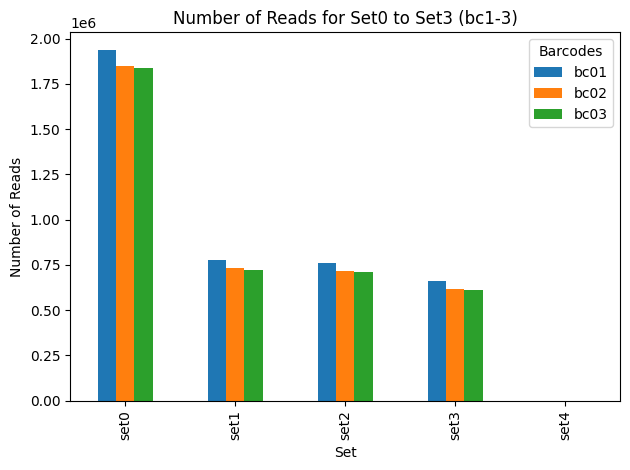

<Figure size 1200x800 with 0 Axes>

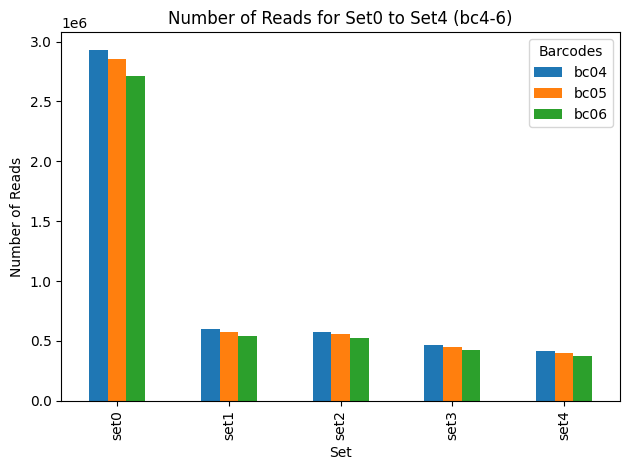

In [1]:
import pandas as pd
import pysam
from Bio import SeqIO
import matplotlib.pyplot as plt

# Function to extract total read counts from BAM files
def extract_total_read_counts(bam_files):
    total_counts = {}
    for bam_file in bam_files:
        count = 0
        with pysam.AlignmentFile(bam_file, "rb") as bam:
            for read in bam.fetch():
                if not read.is_secondary and not read.is_supplementary and not read.is_unmapped:
                    count += 1
        total_counts[bam_file] = count
    return total_counts

# Function to extract read counts from FASTA files
def extract_read_counts_from_fasta(fasta_files):
    reference_counts = {}
    for fasta_file in fasta_files:
        count = sum(1 for _ in SeqIO.parse(fasta_file, "fasta"))
        reference_counts[fasta_file] = count
    return reference_counts

def main():
    # Define BAM file sets
    bam_sets = {
        "set1": [
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc01.aligned_sorted.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc02.aligned_sorted.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc03.aligned_sorted.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc04.aligned_sorted.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc05.aligned_sorted.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc06.aligned_sorted.bam"
        ],
        "set2": [
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc01.aligned_sorted_forward.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc02.aligned_sorted_forward.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc03.aligned_sorted_forward.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc04.aligned_sorted_forward.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc05.aligned_sorted_forward.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc06.aligned_sorted_forward.bam"
        ],
        "set3": [
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc01.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc02.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc03.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc04.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc05.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc06.last_base_filtered.withTN_UI.soft_clipped.sorted.bam"
        ],
        "set4": [
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc04.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc05.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc06.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.bam"
        ]
    }

    # Define FASTA file set0
    fasta_files_set0 = [
        "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc01.fasta",
        "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc02.fasta",
        "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc03.fasta",
        "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc04.fasta",
        "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc05.fasta",
        "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc06.fasta"
    ]

    # Extract read counts for each set
    counts = {}
    counts['set0'] = extract_read_counts_from_fasta(fasta_files_set0)
    for set_name, bam_files in bam_sets.items():
        counts[set_name] = extract_total_read_counts(bam_files)

    # Print counts for debugging
    print("Counts extracted:")
    for set_name, count in counts.items():
        print(f"{set_name}: {count}")

    # Convert counts to DataFrame
    counts_df = pd.DataFrame(counts).fillna(0)

    # Save counts to TSV file
    counts_df.to_csv('read_counts_summary.tsv', sep='\t')

    # Transform data to have columns as bc1 to bc6
    counts_df.index = counts_df.index.str.extract(r'(bc\d+)')[0]
    counts_df = counts_df.groupby(counts_df.index).sum().T

    # Print DataFrame for debugging
    print("Counts DataFrame:")
    print(counts_df)

    # Plot number of reads for set0 to set3 for bc1-3
    plt.figure(figsize=(12, 8))
    counts_df[['bc01', 'bc02', 'bc03']].plot(kind='bar')
    plt.title('Number of Reads for Set0 to Set3 (bc1-3)')
    plt.xlabel('Set')
    plt.ylabel('Number of Reads')
    plt.legend(title='Barcodes')
    plt.tight_layout()
    plt.savefig('number_of_reads_set0_set3_bc1-3.png')
    plt.show()

    # Plot number of reads for set0 to set4 for bc4-6
    plt.figure(figsize=(12, 8))
    counts_df[['bc04', 'bc05', 'bc06']].plot(kind='bar')
    plt.title('Number of Reads for Set0 to Set4 (bc4-6)')
    plt.xlabel('Set')
    plt.ylabel('Number of Reads')
    plt.legend(title='Barcodes')
    plt.tight_layout()
    plt.savefig('number_of_reads_set0_set4_bc4-6.png')
    plt.show()

if __name__ == "__main__":
    main()

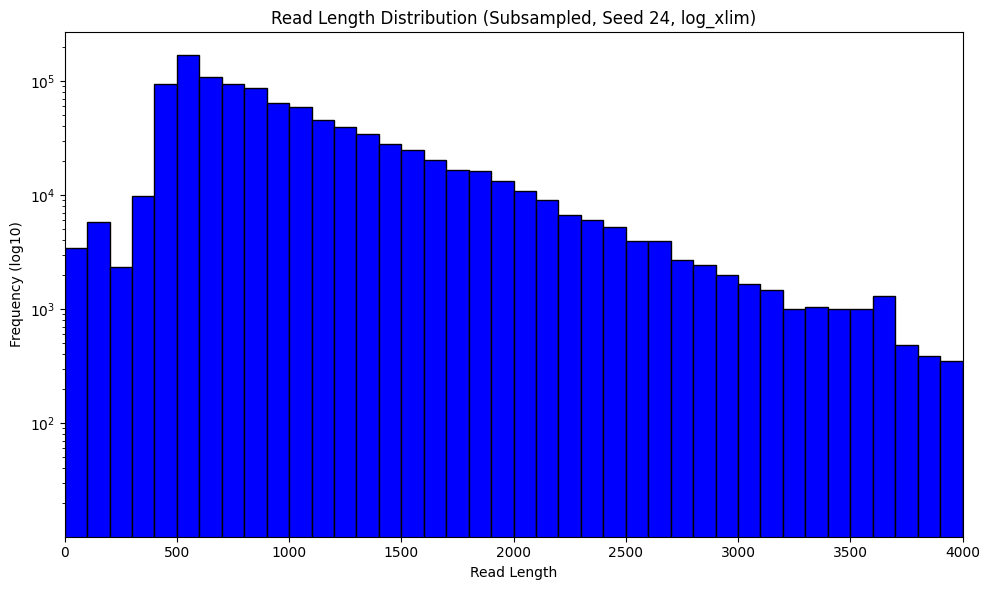

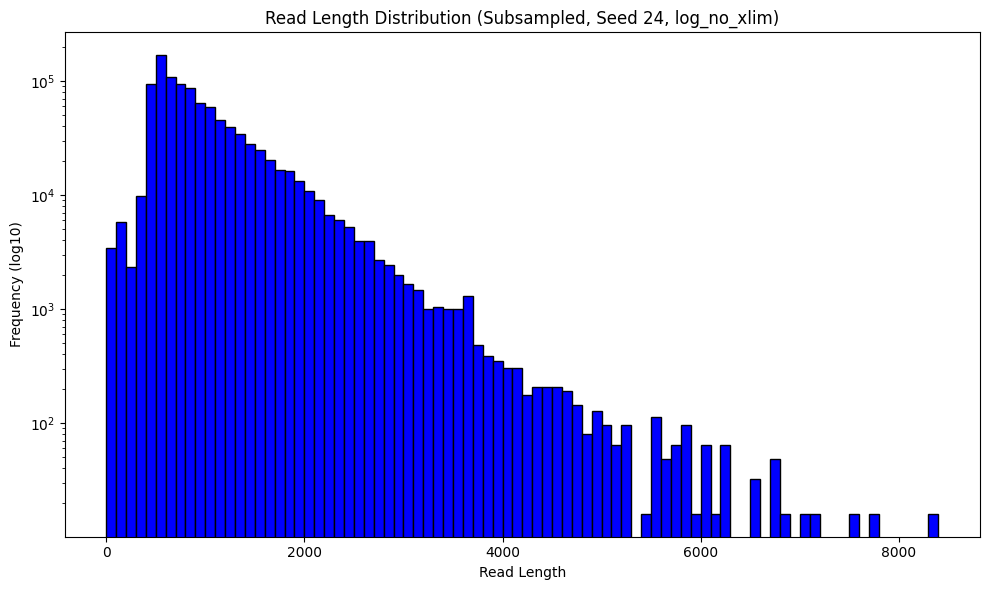

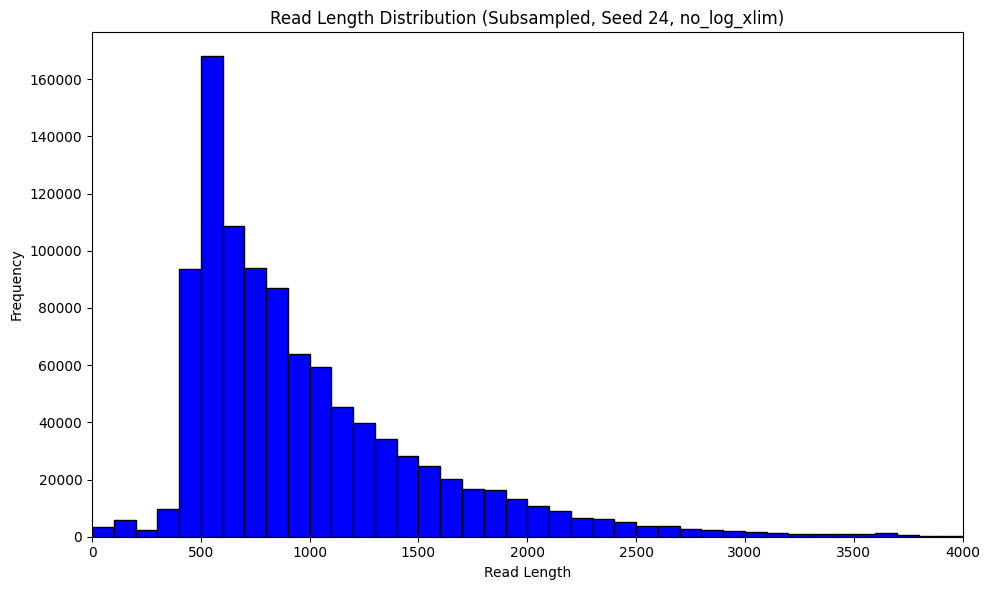

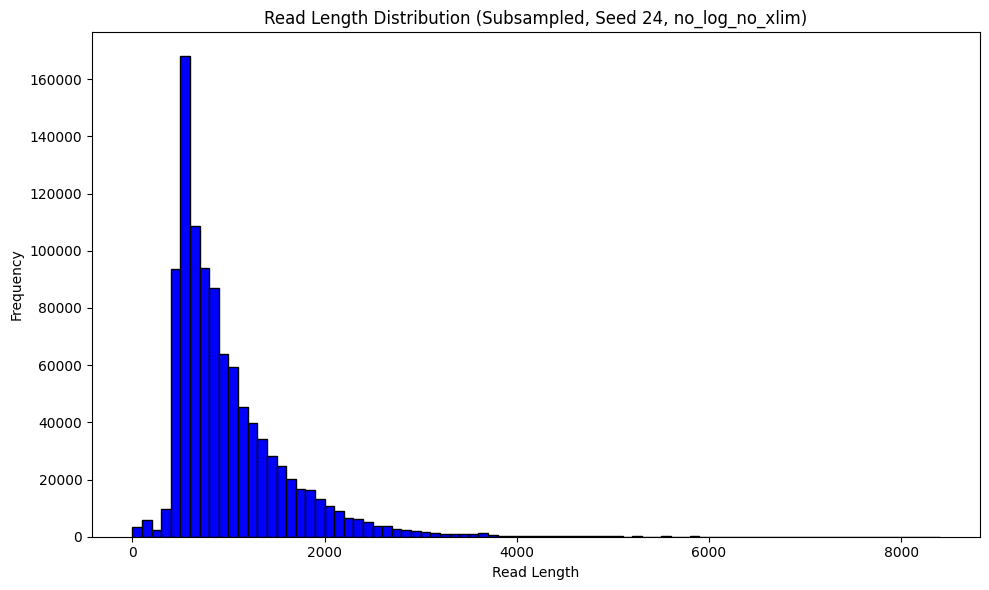

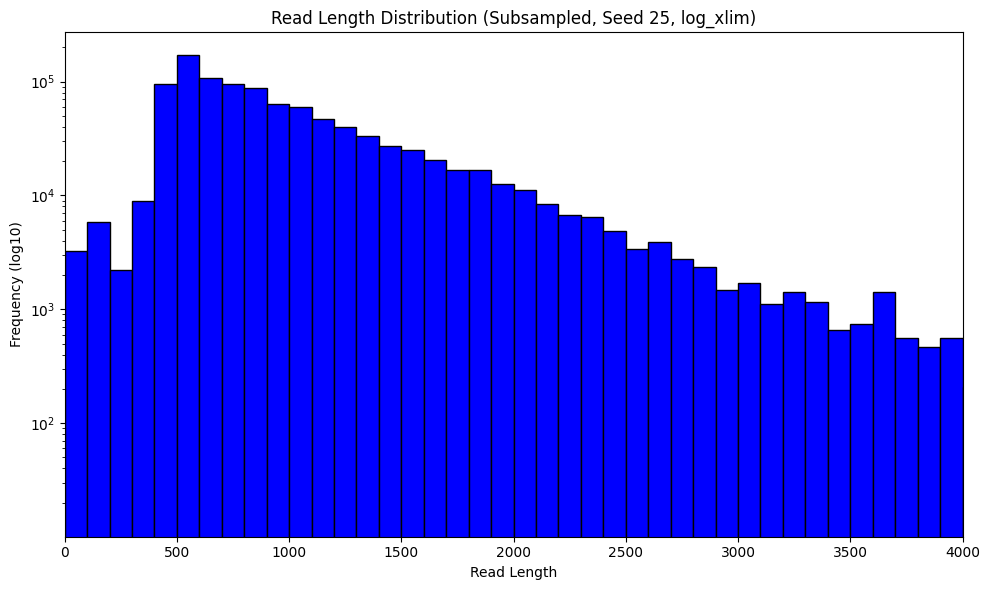

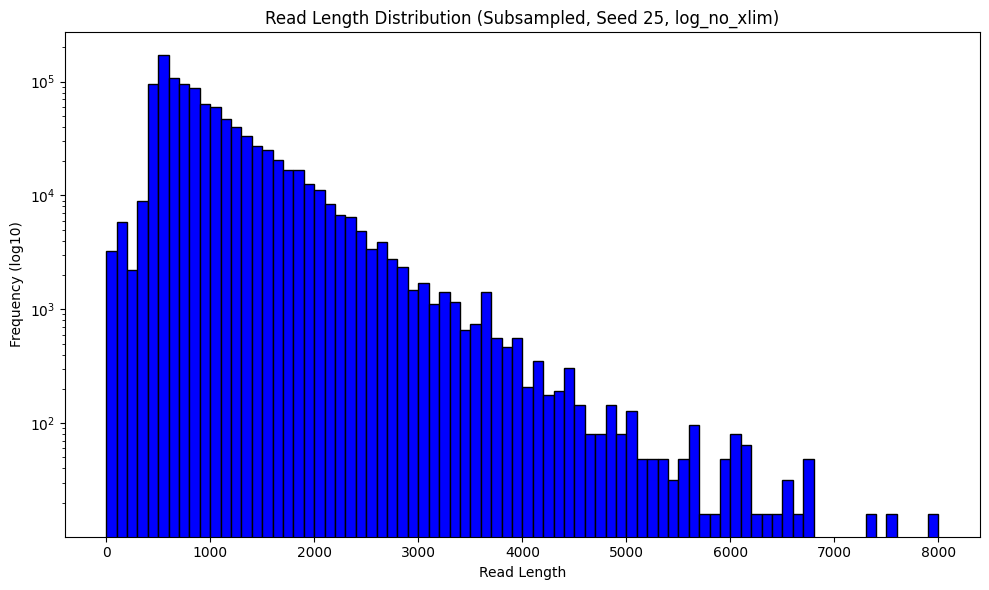

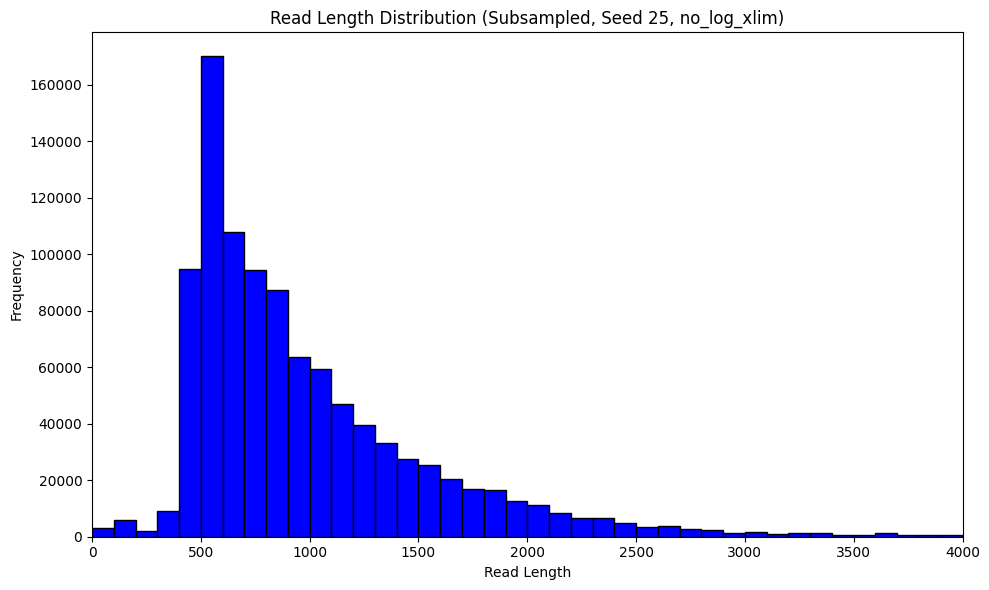

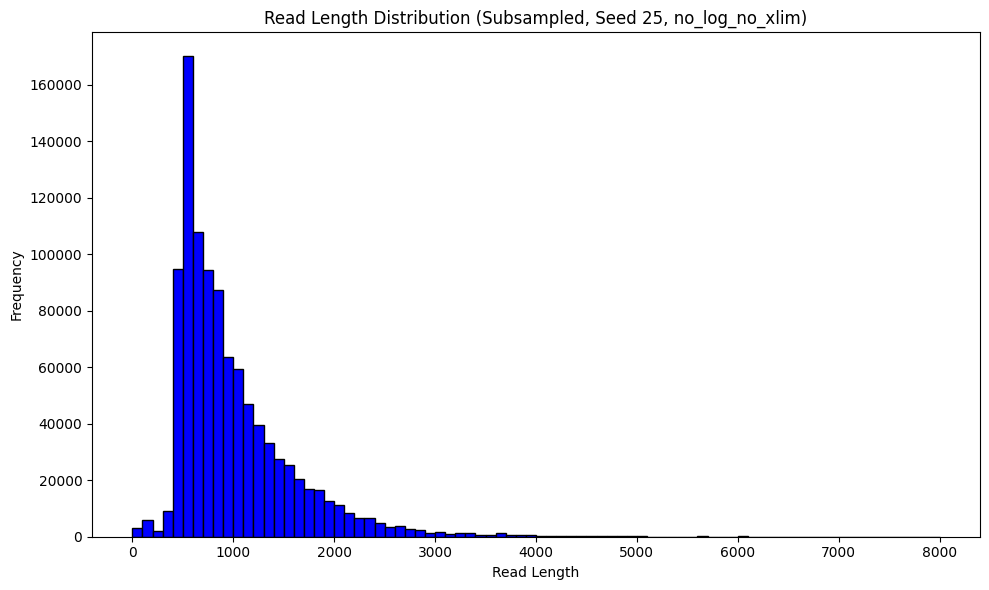

In [3]:
import matplotlib.pyplot as plt
from Bio import SeqIO
import subprocess
import os
from concurrent.futures import ThreadPoolExecutor
import pandas as pd
import numpy as np

# Function to subsample FASTQ files using seqtk
def subsample_fastq_file(fastq_file, output_file, num_samples, seed):
    command = f"/opt/conda/envs/mas_seq/bin/seqtk sample -s{seed} {fastq_file} {num_samples} > {output_file}"
    subprocess.run(command, shell=True, check=True)

# Function to extract read lengths from FASTQ files
def get_read_lengths_from_fastq(fastq_file):
    read_lengths = []
    with open(fastq_file, "rt") as handle:
        for record in SeqIO.parse(handle, "fastq"):
            read_lengths.append(len(record.seq))
    return read_lengths

def process_fastq_file(fastq_file, total_samples, seed):
    subsampled_fastq_file = f"subsampled_{os.path.basename(fastq_file)}_seed{seed}"
    subsample_fastq_file(fastq_file, subsampled_fastq_file, total_samples, seed)
    
    read_lengths = get_read_lengths_from_fastq(subsampled_fastq_file)
    
    if os.path.exists(subsampled_fastq_file):
        os.remove(subsampled_fastq_file)  # Clean up the subsampled FASTQ file
    
    return read_lengths

def plot_read_length_distribution(fastq_file, total_samples=1000000, seeds=[24, 25], max_workers=16):
    for seed in seeds:
        all_read_lengths = []

        with ThreadPoolExecutor(max_workers=max_workers) as executor:
            futures = [executor.submit(process_fastq_file, fastq_file, total_samples // max_workers, seed) for _ in range(max_workers)]
            for future in futures:
                all_read_lengths.extend(future.result())

        # Determine the maximum read length for binning
        max_length = max(all_read_lengths)

        # Define bins
        bins = range(0, max_length + 100, 100)
        
        # Calculate histogram
        hist, bin_edges = np.histogram(all_read_lengths, bins=bins)

        # Save histogram data to TSV file
        tsv_data = pd.DataFrame({
            'Bin_Start': bin_edges[:-1],
            'Bin_End': bin_edges[1:],
            'Frequency': hist
        })
        tsv_data.to_csv(f'read_length_distribution_seed_{seed}.tsv', sep='\t', index=False)

        # Plot configurations
        plot_configs = [
            {"log_scale": True, "xlim": (0, 4000), "suffix": "log_xlim"},
            {"log_scale": True, "xlim": None, "suffix": "log_no_xlim"},
            {"log_scale": False, "xlim": (0, 4000), "suffix": "no_log_xlim"},
            {"log_scale": False, "xlim": None, "suffix": "no_log_no_xlim"}
        ]

        for config in plot_configs:
            plt.figure(figsize=(10, 6))
            plt.hist(all_read_lengths, bins=bins, color='blue', edgecolor='black')
            if config["log_scale"]:
                plt.yscale('log')
            if config["xlim"]:
                plt.xlim(config["xlim"])
            plt.title(f'Read Length Distribution (Subsampled, Seed {seed}, {config["suffix"]})')
            plt.xlabel('Read Length')
            plt.ylabel('Frequency' + (' (log10)' if config["log_scale"] else ''))
            plt.tight_layout()
            plt.savefig(f'read_length_distribution_subsampled_seed{seed}_{config["suffix"]}.png')
            plt.show()

if __name__ == "__main__":
    fastq_file = "10-17-2024_mORF_ONTflow1_barcode15.fastq.gz"
    plot_read_length_distribution(fastq_file)

In [20]:
import matplotlib.pyplot as plt
from Bio import SeqIO
import os
from concurrent.futures import ThreadPoolExecutor
import pandas as pd
import numpy as np
import pysam
import re
import random

def subsample_bulk(data, sample_size, seed):
    random.seed(seed)
    return random.sample(data, min(sample_size, len(data)))

def filter_bam_file(input_bam, num_samples, seed):
    random.seed(seed)
    with pysam.AlignmentFile(input_bam, "rb") as infile:
        reads = [read for read in infile if not read.is_secondary and not read.is_supplementary and not read.is_unmapped]
        subsampled_reads = subsample_bulk(reads, num_samples, seed)
    return subsampled_reads

def subsample_fasta_file(file, num_samples, seed):
    random.seed(seed)
    with open(file, "rt") as handle:
        records = list(SeqIO.parse(handle, "fasta"))
        subsampled_records = subsample_bulk(records, num_samples, seed)
    return subsampled_records

def subsample_file(file, num_samples, seed, file_type):
    if file_type in ["bam", "sam", "cram"]:
        return filter_bam_file(file, num_samples, seed)
    else:
        return subsample_fasta_file(file, num_samples, seed)

def length_distribution_per_worker(worker_data, file_type):
    if file_type in ["bam", "sam", "cram"]:
        return [read.query_length for read in worker_data]
    else:
        return [len(record.seq) for record in worker_data]

def aggregate_lengths(lengths_per_worker):
    aggregated_lengths = []
    for lengths in lengths_per_worker:
        aggregated_lengths.extend(lengths)
    return aggregated_lengths

def extract_barcode(file_name):
    match = re.search(r'bc\d+', file_name)
    return match.group(0) if match else "unknown_bc"

def plot_read_length_distribution(files, set_name, total_samples=1000000, seed=24, max_workers=16, file_type="fastq"):
    for file in files:
        barcode = extract_barcode(file)
        subsampled_data = subsample_file(file, total_samples, seed, file_type)

        # Check the number of subsampled data
        if len(subsampled_data) < total_samples:
            print(f"Warning: Only {len(subsampled_data)} reads available for {file}, expected {total_samples}")

        # Split subsampled data among workers
        chunk_size = len(subsampled_data) // max_workers
        worker_data_chunks = [subsampled_data[i * chunk_size:(i + 1) * chunk_size] for i in range(max_workers)]

        # Handle any remaining data that wasn't evenly divided
        if len(subsampled_data) % max_workers != 0:
            worker_data_chunks[-1].extend(subsampled_data[max_workers * chunk_size:])

        all_read_lengths = []

        with ThreadPoolExecutor(max_workers=max_workers) as executor:
            futures = [executor.submit(length_distribution_per_worker, chunk, file_type) for chunk in worker_data_chunks]
            lengths_per_worker = [future.result() for future in futures]
            all_read_lengths = aggregate_lengths(lengths_per_worker)

        if not all_read_lengths:
            print(f"No read lengths found for file {file}. Skipping plotting.")
            continue

        max_length = max(all_read_lengths)
        bins = range(0, max_length + 100, 100)
        hist, bin_edges = np.histogram(all_read_lengths, bins=bins)

        # Ensure the total frequency is exactly 1 million
        hist = hist * (total_samples / hist.sum())

        tsv_data = pd.DataFrame({
            'Bin_Start': bin_edges[:-1],
            'Bin_End': bin_edges[1:],
            'Frequency': hist
        })
        tsv_data.to_csv(f'{set_name}_{barcode}_read_length_distribution_seed_{seed}.tsv', sep='\t', index=False)

        plot_configs = [
            {"log_scale": True, "xlim": (0, 4000), "suffix": "log_xlim"},
            {"log_scale": True, "xlim": None, "suffix": "log_no_xlim"},
            {"log_scale": False, "xlim": (0, 4000), "suffix": "no_log_xlim"},
            {"log_scale": False, "xlim": None, "suffix": "no_log_no_xlim"}
        ]

        for config in plot_configs:
            plt.figure(figsize=(10, 6))
            plt.hist(all_read_lengths, bins=bins, color='blue', edgecolor='black')
            if config["log_scale"]:
                plt.yscale('log')
            if config["xlim"]:
                plt.xlim(config["xlim"])
            plt.title(f'Read Length Distribution (Subsampled, Seed {seed}, {config["suffix"]})')
            plt.xlabel('Read Length')
            plt.ylabel('Frequency' + (' (log10)' if config["log_scale"] else ''))
            plt.tight_layout()
            plt.savefig(f'{set_name}_{barcode}_read_length_distribution_seed{seed}_{config["suffix"]}.png')
            plt.close()

if __name__ == "__main__":
    bam_sets = {
        "set1": [
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc01.aligned_sorted.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc02.aligned_sorted.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc03.aligned_sorted.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc04.aligned_sorted.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc05.aligned_sorted.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc06.aligned_sorted.bam"
        ],
        "set2": [
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc01.aligned_sorted_forward.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc02.aligned_sorted_forward.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc03.aligned_sorted_forward.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc04.aligned_sorted_forward.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc05.aligned_sorted_forward.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc06.aligned_sorted_forward.bam"
        ],
        "set3": [
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc01.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc02.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc03.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc04.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc05.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc06.last_base_filtered.withTN_UI.soft_clipped.sorted.bam"
        ],
        "set4": [
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc04.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc05.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.bam",
            "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc06.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.bam"
        ]
    }

    fasta_files_set0 = [
        "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc01.fasta",
        "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc02.fasta",
        "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc03.fasta",
        "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc04.fasta",
        "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc05.fasta",
        "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc06.fasta"
    ]
    
    plot_read_length_distribution(fasta_files_set0, "set0", total_samples=1000000, seed=24, file_type="fasta")
    
    for set_name, bam_files in bam_sets.items():
        plot_read_length_distribution(bam_files, set_name, total_samples=1000000, seed=24, file_type="bam")

#### Get Set3/Set2 FC and relavent data for examination

In [ ]:
import pandas as pd
import pysam
from Bio import SeqIO
import numpy as np

# Function to extract read counts from BAM files
def extract_read_counts(bam_files):
    reference_counts = {}
    for bam_file in bam_files:
        with pysam.AlignmentFile(bam_file, "rb") as bam:
            for read in bam.fetch():
                if not read.is_secondary and not read.is_supplementary and not read.is_unmapped:
                    reference_name = bam.get_reference_name(read.reference_id)
                    if reference_name in reference_counts:
                        reference_counts[reference_name] += 1
                    else:
                        reference_counts[reference_name] = 1
    return reference_counts

# Function to extract sequence lengths from FASTA file
def extract_sequence_lengths(fasta_file):
    sequences = {record.id: len(record.seq) for record in SeqIO.parse(fasta_file, "fasta")}
    return sequences

# Function to calculate TPM without accounting for length
def calculate_tpm(counts):
    total_counts = sum(counts.values())
    tpm = {ref: (count / total_counts) * 1e6 for ref, count in counts.items()}
    return tpm

# Define BAM file sets
bam_sets = {
    "set2": [
        "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc04.aligned_sorted_forward.bam",
        "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc05.aligned_sorted_forward.bam",
        "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc06.aligned_sorted_forward.bam"
    ],
    "set3": [
        "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc04.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
        "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc05.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
        "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc06.last_base_filtered.withTN_UI.soft_clipped.sorted.bam"
    ]
}

# Extract sequence lengths from FASTA file
fasta_file = "morf_insert.fasta"
sequence_lengths = extract_sequence_lengths(fasta_file)

# Extract read counts and calculate TPM for each set
tpm_sets = {}
for set_name, bam_files in bam_sets.items():
    tpm_replicates = []
    for bam_file in bam_files:
        counts = extract_read_counts([bam_file])
        tpm = calculate_tpm(counts)
        tpm_replicates.append(tpm)
    # Average TPM across replicates
    avg_tpm = pd.DataFrame(tpm_replicates).mean()
    tpm_sets[set_name] = avg_tpm

# Calculate log2FC for set3 vs set2
log2fc = np.log2(tpm_sets['set3'] / tpm_sets['set2'])

# Create a DataFrame with reference, sequence lengths, log2FC values, and counts for set2 and set3 samples
output_df = pd.DataFrame({
    'Reference': log2fc.index,
    'SeqLength': log2fc.index.map(sequence_lengths),
    'log2FC': log2fc,
    'Counts_set2': tpm_sets['set2'],
    'Counts_set3': tpm_sets['set3']
}).reset_index(drop=True)

# Filter out -inf and NaN values
output_df = output_df.replace([np.inf, -np.inf], np.nan).dropna(subset=['log2FC'])

# Save to TSV file
output_df.to_csv('ONT_set3_vs_set2_per_transcript_summary.tsv', sep='\t', index=False)

In [ ]:
import pysam
import pandas as pd
import subprocess
import os

# Define the input BAM files
bam_files = [
    "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc04.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.bam",
    "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc05.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.bam",
    "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc06.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.bam"
]

# Read the transfer table into a DataFrame
transfer_table = pd.read_csv("transfer_table.tsv", sep="\t")

# Strip whitespace from column names
transfer_table.columns = transfer_table.columns.str.strip()

# Convert the transfer table into a dictionary
transcript_dict = dict(zip(transfer_table["transcript_name"], transfer_table["transcript_id"]))

# Function to convert BAM to FASTA using samtools
def bam_to_fasta_samtools(bam_file, fasta_file):
    command = f"/opt/conda/envs/mas_seq/bin/samtools fasta -T TN,UI {bam_file} > {fasta_file}"
    subprocess.run(command, shell=True, check=True)
    print(f"Converted {bam_file} to {fasta_file}")

# Function to filter and update TN tag in FASTA file
def filter_and_update_fasta(fasta_file, updated_fasta_file, transcript_dict):
    total_reads = 0
    matched_reads = 0
    with open(fasta_file, "r") as infile, open(updated_fasta_file, "w") as outfile:
        for line in infile:
            if line.startswith(">"):
                total_reads += 1
                header = line.strip()
                seq_name = header.split()[0][1:]
                tn_tag = header.split("TN:")[1].split()[0] if "TN:" in header else ""
                tn_tag = tn_tag.replace("Z:", "")  # Remove the Z: prefix
                if tn_tag in transcript_dict:
                    matched_reads += 1
                    new_tn_tag = transcript_dict[tn_tag]
                    ui_tag = header.split("UI:")[1] if "UI:" in header else ""
                    new_header = f">{seq_name}\tTN:Z:{new_tn_tag}\tUI:{ui_tag}"
                    outfile.write(f"{new_header}\n")
                    seq = next(infile).strip()
                    outfile.write(f"{seq}\n")
    
    print(f"Processed {fasta_file}")
    print(f"Total reads: {total_reads}")
    print(f"Matched reads: {matched_reads}")

# Function to map FASTA to reference genome using minimap2 and convert to sorted BAM
def map_fasta_to_bam_first(fasta_file, bam_file, reference_fa):
    sorted_bam_file = bam_file.replace(".bam", "_sorted.bam")
    command = (
        f"/opt/conda/envs/mas_seq/bin/minimap2 -y --secondary=no -a -t 4 {reference_fa} {fasta_file} | "
        f"/opt/conda/envs/mas_seq/bin/samtools view -b | "
        f"/opt/conda/envs/mas_seq/bin/samtools sort -o {sorted_bam_file}"
    )
    try:
        subprocess.run(command, shell=True, check=True)
    except subprocess.CalledProcessError as e:
        print(f"Error running minimap2 and samtools pipeline: {e}")
        return None
    
    return sorted_bam_file

# Function to map trimmed FASTA to reference genome using minimap2 and convert to sorted BAM
def map_fasta_to_bam_second(fasta_file, bam_file, reference_fa, junc_bed):
    sorted_bam_file = bam_file.replace(".bam", "_final_sorted.bam")
    command = (
        f"/opt/conda/envs/mas_seq/bin/minimap2 -y -a -uf -x splice --secondary=yes -Y --MD -t 4 --cs=long "
        f"--junc-bed {junc_bed} {reference_fa} {fasta_file} | "
        f"/opt/conda/envs/mas_seq/bin/samtools view -b | "
        f"/opt/conda/envs/mas_seq/bin/samtools sort -o {sorted_bam_file}"
    )
    try:
        subprocess.run(command, shell=True, check=True)
    except subprocess.CalledProcessError as e:
        print(f"Error running minimap2 and samtools pipeline: {e}")
        return None
    
    return sorted_bam_file

# Function to remove soft clipping from a read and return the trimmed sequence
def trim_soft_clipping(read):
    if read.cigartuples is None:
        return read.query_sequence

    new_seq = read.query_sequence
    start = 0
    end = len(new_seq)

    # Trim 5' soft clipping
    if read.cigartuples[0][0] == 4:  # Soft clipping (S) at the beginning
        start = read.cigartuples[0][1]

    # Trim 3' soft clipping
    if read.cigartuples[-1][0] == 4:  # Soft clipping (S) at the end
        end -= read.cigartuples[-1][1]

    return new_seq[start:end]

# Function to convert BAM to FASTA, trimming soft clipping based on CIGAR
def bam_to_fasta_trimmed(bam_file, fasta_file):
    total_reads = 0
    trimmed_reads = 0
    with pysam.AlignmentFile(bam_file, "rb") as infile, open(fasta_file, "w") as outfile:
        for read in infile:
            if read.is_secondary or read.is_supplementary or read.is_unmapped or read.is_reverse:
                continue  # Skip secondary, supplementary, unmapped, and reverse strand reads
            
            total_reads += 1
            trimmed_seq = trim_soft_clipping(read)
            if trimmed_seq:
                trimmed_reads += 1
                tn_tag = read.get_tag("TN") if read.has_tag("TN") else ""
                ui_tag = read.get_tag("UI") if read.has_tag("UI") else ""
                header = f">{read.query_name}\tTN:Z:{tn_tag}"
                if ui_tag:
                    header += f"\tUI:Z:{ui_tag}"
                outfile.write(f"{header}\n")
                outfile.write(f"{trimmed_seq}\n")
    
    print(f"Processed {bam_file}")
    print(f"Total reads: {total_reads}")
    print(f"Trimmed reads: {trimmed_reads}")

# Function to index the final BAM file
def index_bam(bam_file):
    command = f"/opt/conda/envs/mas_seq/bin/samtools index {bam_file}"
    subprocess.run(command, shell=True, check=True)

def main():
    reference_fa_first = "/home/jupyter/projects/morf/morf.fasta"
    reference_fa_second = "minigenome.fa"
    junc_bed = "minigenome.UTRs_trimmed.bed"

    for bam_file in bam_files:
        # Step 1: Convert the original BAM file to FASTA using samtools
        fasta_file = bam_file.replace(".bam", ".fasta")
        bam_to_fasta_samtools(bam_file, fasta_file)
        
        # Step 2: Filter and update TN tag in the FASTA file
        updated_fasta_file = fasta_file.replace(".fasta", "_updated.fasta")
        filter_and_update_fasta(fasta_file, updated_fasta_file, transcript_dict)
        
        # Step 3: Map the updated FASTA reads to the genome and convert to sorted BAM (first run)
        bam_file_output = bam_file.replace(".bam", "_mapped.bam")
        sorted_bam_file = map_fasta_to_bam_first(updated_fasta_file, bam_file_output, reference_fa_first)
        
        # Step 4: Convert the sorted BAM file to FASTA, trimming soft clipping
        trimmed_fasta_file = sorted_bam_file.replace(".bam", ".trimmed.fasta")
        bam_to_fasta_trimmed(sorted_bam_file, trimmed_fasta_file)
        
        # Step 5: Map the trimmed FASTA file to the genome and convert to sorted BAM (second run)
        final_bam_file = trimmed_fasta_file.replace(".fasta", ".bam")
        final_sorted_bam_file = map_fasta_to_bam_second(trimmed_fasta_file, final_bam_file, reference_fa_second, junc_bed)
        
        # Step 6: Index the final sorted BAM file
        index_bam(final_sorted_bam_file)

if __name__ == "__main__":
    main()

[M::bam2fq_mainloop] discarded 0 singletons
[M::bam2fq_mainloop] processed 411977 reads


Converted 2024_mORF_ONTflow1_barcode15_trimmed_reads_bc04.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.bam to 2024_mORF_ONTflow1_barcode15_trimmed_reads_bc04.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.fasta
Processed 2024_mORF_ONTflow1_barcode15_trimmed_reads_bc04.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.fasta
Total reads: 411977
Matched reads: 375162


[M::mm_idx_gen::0.695*0.38] collected minimizers
[M::mm_idx_gen::0.748*0.63] sorted minimizers
[M::main::0.749*0.63] loaded/built the index for 3550 target sequence(s)
[M::mm_mapopt_update::0.768*0.64] mid_occ = 53
[M::mm_idx_stat] kmer size: 15; skip: 10; is_hpc: 0; #seq: 3550
[M::mm_idx_stat::0.780*0.64] distinct minimizers: 573568 (52.66% are singletons); average occurrences: 1.969; average spacing: 5.407; total length: 6105645
[M::worker_pipeline::86.290*3.72] mapped 375162 sequences
[M::main] Version: 2.28-r1209
[M::main] CMD: /opt/conda/envs/mas_seq/bin/minimap2 -y --secondary=no -a -t 4 /home/jupyter/projects/morf/morf.fasta 2024_mORF_ONTflow1_barcode15_trimmed_reads_bc04.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup_updated.fasta
[M::main] Real time: 86.305 sec; CPU: 321.104 sec; Peak RSS: 0.584 GB


Processed 2024_mORF_ONTflow1_barcode15_trimmed_reads_bc04.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup_mapped_sorted.bam
Total reads: 366065
Trimmed reads: 366065


[M::mm_idx_gen::1.492*0.98] collected minimizers
[M::mm_idx_gen::1.792*1.48] sorted minimizers
[M::main::1.792*1.48] loaded/built the index for 1566 target sequence(s)
[M::mm_mapopt_update::1.985*1.43] mid_occ = 89
[M::mm_idx_stat] kmer size: 15; skip: 5; is_hpc: 0; #seq: 1566
[M::mm_idx_stat::2.125*1.40] distinct minimizers: 7849055 (91.84% are singletons); average occurrences: 1.228; average spacing: 2.932; total length: 28250975
[M::worker_pipeline::170.502*3.83] mapped 366065 sequences
[M::main] Version: 2.28-r1209
[M::main] CMD: /opt/conda/envs/mas_seq/bin/minimap2 -y -a -uf -x splice --secondary=yes -Y --MD -t 4 --cs=long --junc-bed minigenome.UTRs_trimmed.bed minigenome.fa 2024_mORF_ONTflow1_barcode15_trimmed_reads_bc04.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup_mapped_sorted.trimmed.fasta
[M::main] Real time: 170.540 sec; CPU: 653.524 sec; Peak RSS: 1.042 GB
[M::bam2fq_mainloop] discarded 0 singletons
[M::bam2fq_mainloop] processed 397895 reads


Converted 2024_mORF_ONTflow1_barcode15_trimmed_reads_bc05.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.bam to 2024_mORF_ONTflow1_barcode15_trimmed_reads_bc05.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.fasta
Processed 2024_mORF_ONTflow1_barcode15_trimmed_reads_bc05.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.fasta
Total reads: 397895
Matched reads: 362339


... (3 outputs left out)

Converted 2024_mORF_ONTflow1_barcode15_trimmed_reads_bc06.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.bam to 2024_mORF_ONTflow1_barcode15_trimmed_reads_bc06.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.fasta
Processed 2024_mORF_ONTflow1_barcode15_trimmed_reads_bc06.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.fasta
Total reads: 374352
Matched reads: 341323


[M::mm_idx_gen::0.240*1.01] collected minimizers
[M::mm_idx_gen::0.305*1.59] sorted minimizers
[M::main::0.306*1.59] loaded/built the index for 3550 target sequence(s)
[M::mm_mapopt_update::0.327*1.55] mid_occ = 53
[M::mm_idx_stat] kmer size: 15; skip: 10; is_hpc: 0; #seq: 3550
[M::mm_idx_stat::0.340*1.53] distinct minimizers: 573568 (52.66% are singletons); average occurrences: 1.969; average spacing: 5.407; total length: 6105645
[M::worker_pipeline::77.887*3.74] mapped 341323 sequences
[M::main] Version: 2.28-r1209
[M::main] CMD: /opt/conda/envs/mas_seq/bin/minimap2 -y --secondary=no -a -t 4 /home/jupyter/projects/morf/morf.fasta 2024_mORF_ONTflow1_barcode15_trimmed_reads_bc06.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup_updated.fasta
[M::main] Real time: 77.899 sec; CPU: 291.469 sec; Peak RSS: 0.554 GB


Processed 2024_mORF_ONTflow1_barcode15_trimmed_reads_bc06.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup_mapped_sorted.bam
Total reads: 333507
Trimmed reads: 333507


[M::mm_idx_gen::1.421*1.00] collected minimizers
[M::mm_idx_gen::1.719*1.51] sorted minimizers
[M::main::1.719*1.51] loaded/built the index for 1566 target sequence(s)
[M::mm_mapopt_update::1.914*1.46] mid_occ = 89
[M::mm_idx_stat] kmer size: 15; skip: 5; is_hpc: 0; #seq: 1566
[M::mm_idx_stat::2.059*1.43] distinct minimizers: 7849055 (91.84% are singletons); average occurrences: 1.228; average spacing: 2.932; total length: 28250975
[M::worker_pipeline::146.393*3.83] mapped 333507 sequences
[M::main] Version: 2.28-r1209
[M::main] CMD: /opt/conda/envs/mas_seq/bin/minimap2 -y -a -uf -x splice --secondary=yes -Y --MD -t 4 --cs=long --junc-bed minigenome.UTRs_trimmed.bed minigenome.fa 2024_mORF_ONTflow1_barcode15_trimmed_reads_bc06.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup_mapped_sorted.trimmed.fasta
[M::main] Real time: 146.437 sec; CPU: 560.668 sec; Peak RSS: 0.858 GB


In [ ]:
import os

# Define the base directory where your files are located
base_dir = "."

# Define the file names
files = [
    "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc04.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup_mapped_sorted.trimmed_final_sorted_annot_compat.bam",
    "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc05.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup_mapped_sorted.trimmed_final_sorted_annot_compat.bam",
    "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc06.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup_mapped_sorted.trimmed_final_sorted_annot_compat.bam"
]

# Function to get the full file path
def get_file_path(file_name):
    return os.path.join(base_dir, file_name)

# Print file sizes
for file in files:
    file_path = get_file_path(file)
    if os.path.exists(file_path):
        file_size = os.path.getsize(file_path)
        print(f"File: {file}\nSize: {file_size} bytes\n")
    else:
        print(f"File: {file} does not exist\n")

File: 2024_mORF_ONTflow1_barcode15_trimmed_reads_bc04.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup_mapped_sorted.trimmed_final_sorted_annot_compat.bam
Size: 53082490 bytes

File: 2024_mORF_ONTflow1_barcode15_trimmed_reads_bc05.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup_mapped_sorted.trimmed_final_sorted_annot_compat.bam
Size: 51186637 bytes

File: 2024_mORF_ONTflow1_barcode15_trimmed_reads_bc06.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup_mapped_sorted.trimmed_final_sorted_annot_compat.bam
Size: 48172970 bytes



In [ ]:
#!/usr/bin/env python

import os
import subprocess
import shutil

def clear_tc_tmp_folder():
    tc_tmp_folder = "TC_tmp"
    if os.path.exists(tc_tmp_folder):
        shutil.rmtree(tc_tmp_folder)
    os.makedirs(tc_tmp_folder)

def convert_bam_to_sam_and_run_transcriptclean(bam_file, genome_fa, outprefix):
    clear_tc_tmp_folder()
    sam_file = bam_file.replace(".bam", ".sam")
    command = f"/opt/conda/envs/mas_seq/bin/samtools view -h {bam_file} > {sam_file}"
    subprocess.run(command, shell=True, check=True)
    command = f"/opt/conda/envs/mas_seq/bin/transcriptclean --sam {sam_file} --genome {genome_fa} --outprefix {outprefix} --threads 5"
    subprocess.run(command, shell=True, check=True)
    os.remove(sam_file)

def main():
    bam_files = [
        "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc04.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup_mapped_sorted.trimmed_final_sorted_annot_compat.bam",
        "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc05.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup_mapped_sorted.trimmed_final_sorted_annot_compat.bam",
        "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc06.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup_mapped_sorted.trimmed_final_sorted_annot_compat.bam"
    ]
    
    genome_fa = "minigenome.fa"

    for bam_file in bam_files:
        outprefix = os.path.splitext(bam_file)[0] + "_transcriptclean"
        try:
            convert_bam_to_sam_and_run_transcriptclean(bam_file, genome_fa, outprefix)
        except Exception as exc:
            print(f"Generated an exception: {exc}")

if __name__ == '__main__':
    main()

Reading genome ..............................
No splice annotation provided. Will skip splice junction correction.
No variant file provided. Transcript correction will not be variant-aware.
Reference file processing took 0:00:00
Correcting transcripts...
Took 0:13:16 to process transcript batch.
Reading genome ..............................
No splice annotation provided. Will skip splice junction correction.
No variant file provided. Transcript correction will not be variant-aware.
Reference file processing took 0:00:00
Correcting transcripts...
Took 0:13:25 to process transcript batch.
Reading genome ..............................
No splice annotation provided. Will skip splice junction correction.
No variant file provided. Transcript correction will not be variant-aware.
Reference file processing took 0:00:00
Correcting transcripts...
Took 0:13:54 to process transcript batch.
Reading genome ..............................
No splice annotation provided. Will skip splice junction correc

In [6]:
#!/usr/bin/env python

import os
import subprocess

def convert_sam_to_bam(sam_file):
    bam_file = sam_file.replace(".sam", ".bam")
    command = f"/opt/conda/envs/mas_seq/bin/samtools view -b {sam_file} > {bam_file}"
    subprocess.run(command, shell=True, check=True)
    return bam_file

def main():
    sam_files = [
        "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc04.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup_mapped_sorted.trimmed_final_sorted_annot_compat_transcriptclean_clean.sam",
        "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc05.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup_mapped_sorted.trimmed_final_sorted_annot_compat_transcriptclean_clean.sam",
        "2024_mORF_ONTflow1_barcode15_trimmed_reads_bc06.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup_mapped_sorted.trimmed_final_sorted_annot_compat_transcriptclean_clean.sam"
    ]

    # Convert SAM files to BAM files
    bam_files = [convert_sam_to_bam(sam_file) for sam_file in sam_files]

    # Merge BAM files
    merged_bam_file = "morf2_ont_merged_transcriptclean.bam"
    command = f"/opt/conda/envs/mas_seq/bin/samtools merge -f {merged_bam_file} " + " ".join(bam_files)
    subprocess.run(command, shell=True, check=True)

    # Sort the merged BAM file
    sorted_bam_file = "morf2_ont_merged_transcriptclean_sorted.bam"
    command = f"/opt/conda/envs/mas_seq/bin/samtools sort {merged_bam_file} -o {sorted_bam_file}"
    subprocess.run(command, shell=True, check=True)

    # Index the sorted BAM file
    command = f"/opt/conda/envs/mas_seq/bin/samtools index {sorted_bam_file}"
    subprocess.run(command, shell=True, check=True)

if __name__ == '__main__':
    main()

[bam_sort_core] merging from 1 files and 1 in-memory blocks...


In [13]:
#!/usr/bin/env python

import pysam
from collections import defaultdict

def count_tn_occurrences(bam_file, output_tsv):
    tn_counts = defaultdict(int)
    total_reads = 0
    
    with pysam.AlignmentFile(bam_file, "rb") as infile:
        for read in infile:
            if read.is_secondary or read.is_unmapped or read.is_supplementary:
                continue  # Skip secondary, unmapped, and supplementary alignments
            
            total_reads += 1
            
            if read.has_tag("TN"):
                tn_tag = read.get_tag("TN")
                tn_counts[tn_tag] += 1
    
    with open(output_tsv, "w") as outfile:
        for tn_tag, count in tn_counts.items():
            outfile.write(f"{tn_tag}\t{count}\n")
    
    print(f"Total number of reads processed: {total_reads}")

def main():
    bam_file = "morf2_ont_merged_annot_compat_sorted.bam"
    output_tsv = "morf2_ont_merged_annot_compat_sorted_tn_counts.tsv"
    count_tn_occurrences(bam_file, output_tsv)

if __name__ == '__main__':
    main()

Total number of reads processed: 1010278


In [2]:
#!/usr/bin/env python

import random
import pandas as pd
import gffutils
from collections import defaultdict

def parse_gtf(gtf_file):
    db = gffutils.create_db(gtf_file, dbfn=':memory:', force=True, keep_order=True, merge_strategy='merge', sort_attribute_values=True, disable_infer_transcripts=True, disable_infer_genes=True)
    genes = defaultdict(lambda: defaultdict(list))
    for feature in db.all_features():
        if feature.featuretype == 'transcript':
            gene_id = feature.attributes.get('gene_id', [None])[0]
            transcript_id = feature.attributes.get('transcript_id', [None])[0]
            genes[gene_id][transcript_id].append(feature)
        elif feature.featuretype in ['exon', 'CDS']:
            gene_id = feature.attributes.get('gene_id', [None])[0]
            transcript_id = feature.attributes.get('transcript_id', [None])[0]
            genes[gene_id][transcript_id].append(feature)
    return genes

def write_gtf(genes, output_file):
    with open(output_file, "w") as outfile:
        for gene_id, transcripts in genes.items():
            for transcript_id, features in transcripts.items():
                for feature in features:
                    outfile.write(str(feature) + "\n")

def generate_reduced_gtf(genes, output_file, percentage=80):
    random.seed(42)
    reduced_genes = defaultdict(lambda: defaultdict(list))
    for gene_id, transcripts in genes.items():
        transcript_ids = list(transcripts.keys())
        if percentage == 100:
            # Select only one transcript per gene
            selected_transcripts = [random.choice(transcript_ids)]
        else:
            if len(transcript_ids) > 1:
                num_to_keep = max(1, int(len(transcript_ids) * (percentage / 100.0)))
                selected_transcripts = random.sample(transcript_ids, num_to_keep)
            else:
                # Randomly decide whether to keep the single transcript
                selected_transcripts = transcript_ids if random.random() < (percentage / 100.0) else []
        for transcript_id in selected_transcripts:
            reduced_genes[gene_id][transcript_id] = transcripts[transcript_id]
    # Remove genes with no transcripts
    reduced_genes = {gene_id: transcripts for gene_id, transcripts in reduced_genes.items() if transcripts}
    write_gtf(reduced_genes, output_file)
    return reduced_genes

def generate_expressed_gtf(genes, tn_counts, output_file):
    expressed_genes = defaultdict(lambda: defaultdict(list))
    for gene_id, transcripts in genes.items():
        for transcript_id in transcripts.keys():
            if transcript_id in tn_counts:
                expressed_genes[gene_id][transcript_id] = transcripts[transcript_id]
    # Remove genes with no transcripts
    expressed_genes = {gene_id: transcripts for gene_id, transcripts in expressed_genes.items() if transcripts}
    write_gtf(expressed_genes, output_file)
    return expressed_genes

def generate_expressed_kept_gtf(reduced_genes, expressed_genes, output_file):
    expressed_kept_genes = defaultdict(lambda: defaultdict(list))
    for gene_id, transcripts in reduced_genes.items():
        if gene_id in expressed_genes:
            for transcript_id in transcripts.keys():
                if transcript_id in expressed_genes[gene_id]:
                    expressed_kept_genes[gene_id][transcript_id] = transcripts[transcript_id]
    # Remove genes with no transcripts
    expressed_kept_genes = {gene_id: transcripts for gene_id, transcripts in expressed_kept_genes.items() if transcripts}
    write_gtf(expressed_kept_genes, output_file)
    return expressed_kept_genes

def count_genes_and_transcripts(genes):
    num_genes = len(genes)
    num_transcripts = sum(len(transcripts) for transcripts in genes.values())
    return num_genes, num_transcripts

def main():
    gtf_file = "minigenome.UTRs_trimmed.gtf"
    tn_counts_file = "morf2_ont_merged_annot_compat_sorted_tn_counts.tsv"
    
    # Parse GTF file
    genes = parse_gtf(gtf_file)
    original_num_genes, original_num_transcripts = count_genes_and_transcripts(genes)
    print(f"Original GTF: {original_num_genes} genes, {original_num_transcripts} transcripts")
    
    # Parse TN counts file
    tn_counts_df = pd.read_csv(tn_counts_file, sep="\t", header=None, index_col=False)
    tn_counts = tn_counts_df.set_index(0)[1].to_dict()
    print(f"TN counts: {len(tn_counts)} transcripts")
    
    # Generate reduced GTF files
    reduced_80percent_genes = generate_reduced_gtf(genes, "minigenome.UTRs_trimmed_80percentref_reduced.gtf", percentage=80)
    reduced_1isoform_genes = generate_reduced_gtf(genes, "minigenome.UTRs_trimmed_1isoformref_reduced.gtf", percentage=100)
    
    reduced_80percent_num_genes, reduced_80percent_num_transcripts = count_genes_and_transcripts(reduced_80percent_genes)
    reduced_1isoform_num_genes, reduced_1isoform_num_transcripts = count_genes_and_transcripts(reduced_1isoform_genes)
    
    print(f"Reduced 80% GTF: {reduced_80percent_num_genes} genes, {reduced_80percent_num_transcripts} transcripts")
    print(f"Reduced 1 isoform GTF: {reduced_1isoform_num_genes} genes, {reduced_1isoform_num_transcripts} transcripts")
    
    # Generate expressed GTF files
    expressed_80percent_genes = generate_expressed_gtf(genes, tn_counts, "minigenome.UTRs_trimmed_80percentref_expressed.gtf")
    expressed_1isoform_genes = generate_expressed_gtf(genes, tn_counts, "minigenome.UTRs_trimmed_1isoformref_expressed.gtf")
    
    expressed_80percent_num_genes, expressed_80percent_num_transcripts = count_genes_and_transcripts(expressed_80percent_genes)
    expressed_1isoform_num_genes, expressed_1isoform_num_transcripts = count_genes_and_transcripts(expressed_1isoform_genes)
    
    print(f"Expressed 80% GTF: {expressed_80percent_num_genes} genes, {expressed_80percent_num_transcripts} transcripts")
    print(f"Expressed 1 isoform GTF: {expressed_1isoform_num_genes} genes, {expressed_1isoform_num_transcripts} transcripts")
    
    # Generate expressed_kept GTF files
    expressed_kept_80percent_genes = generate_expressed_kept_gtf(reduced_80percent_genes, expressed_80percent_genes, "minigenome.UTRs_trimmed_80percentref_expressed_kept.gtf")
    expressed_kept_1isoform_genes = generate_expressed_kept_gtf(reduced_1isoform_genes, expressed_1isoform_genes, "minigenome.UTRs_trimmed_1isoformref_expressed_kept.gtf")
    
    expressed_kept_80percent_num_genes, expressed_kept_80percent_num_transcripts = count_genes_and_transcripts(expressed_kept_80percent_genes)
    expressed_kept_1isoform_num_genes, expressed_kept_1isoform_num_transcripts = count_genes_and_transcripts(expressed_kept_1isoform_genes)
    
    print(f"Expressed kept 80% GTF: {expressed_kept_80percent_num_genes} genes, {expressed_kept_80percent_num_transcripts} transcripts")
    print(f"Expressed kept 1 isoform GTF: {expressed_kept_1isoform_num_genes} genes, {expressed_kept_1isoform_num_transcripts} transcripts")

if __name__ == '__main__':
    main()

Original GTF: 1566 genes, 2923 transcripts
TN counts: 2892 transcripts
Reduced 80% GTF: 1384 genes, 1995 transcripts
Reduced 1 isoform GTF: 1566 genes, 1566 transcripts
Expressed 80% GTF: 1553 genes, 2892 transcripts
Expressed 1 isoform GTF: 1553 genes, 2892 transcripts
Expressed kept 80% GTF: 1374 genes, 1977 transcripts
Expressed kept 1 isoform GTF: 1545 genes, 1545 transcripts


In [9]:
### To ensure that the records are ordered correctly (gene, transcript, exon) and to remove all CDS records, we updated the write_gtf function. Here is the updated script:
#!/usr/bin/env python

import random
import pandas as pd
import gffutils
from collections import defaultdict

def parse_gtf(gtf_file):
    db = gffutils.create_db(gtf_file, dbfn=':memory:', force=True, keep_order=True, merge_strategy='merge', sort_attribute_values=True, disable_infer_transcripts=True, disable_infer_genes=True)
    genes = defaultdict(lambda: defaultdict(list))
    for feature in db.all_features():
        if feature.featuretype == 'transcript':
            gene_id = feature.attributes.get('gene_id', [None])[0]
            transcript_id = feature.attributes.get('transcript_id', [None])[0]
            genes[gene_id][transcript_id].append(feature)
        elif feature.featuretype in ['exon']:
            gene_id = feature.attributes.get('gene_id', [None])[0]
            transcript_id = feature.attributes.get('transcript_id', [None])[0]
            genes[gene_id][transcript_id].append(feature)
    return genes

def write_gtf(genes, output_file, original_gtf):
    gene_records = {}
    with open(original_gtf) as infile:
        for line in infile:
            if "\tgene\t" in line:
                gene_id = line.split('gene_id "')[1].split('"')[0]
                gene_records[gene_id] = line

    with open(output_file, "w") as outfile:
        for gene_id, transcripts in genes.items():
            if gene_id in gene_records:
                outfile.write(gene_records[gene_id])
            for transcript_id, features in transcripts.items():
                transcripts = [f for f in features if f.featuretype == 'transcript']
                exons = [f for f in features if f.featuretype == 'exon']
                for transcript in transcripts:
                    outfile.write(str(transcript) + "\n")
                for exon in exons:
                    outfile.write(str(exon) + "\n")

def generate_reduced_gtf(genes, output_file, original_gtf, percentage=80):
    random.seed(42)
    reduced_genes = defaultdict(lambda: defaultdict(list))
    for gene_id, transcripts in genes.items():
        transcript_ids = list(transcripts.keys())
        if percentage == 100:
            # Select only one transcript per gene
            selected_transcripts = [random.choice(transcript_ids)]
        else:
            if len(transcript_ids) > 1:
                num_to_keep = max(1, int(len(transcript_ids) * (percentage / 100.0)))
                selected_transcripts = random.sample(transcript_ids, num_to_keep)
            else:
                # Randomly decide whether to keep the single transcript
                selected_transcripts = transcript_ids if random.random() < (percentage / 100.0) else []
        for transcript_id in selected_transcripts:
            reduced_genes[gene_id][transcript_id] = transcripts[transcript_id]
    # Remove genes with no transcripts
    reduced_genes = {gene_id: transcripts for gene_id, transcripts in reduced_genes.items() if transcripts}
    write_gtf(reduced_genes, output_file, original_gtf)
    return reduced_genes

def generate_expressed_gtf(genes, tn_counts, output_file, original_gtf):
    expressed_genes = defaultdict(lambda: defaultdict(list))
    for gene_id, transcripts in genes.items():
        for transcript_id in transcripts.keys():
            if transcript_id in tn_counts:
                expressed_genes[gene_id][transcript_id] = transcripts[transcript_id]
    # Remove genes with no transcripts
    expressed_genes = {gene_id: transcripts for gene_id, transcripts in expressed_genes.items() if transcripts}
    write_gtf(expressed_genes, output_file, original_gtf)
    return expressed_genes

def generate_expressed_kept_gtf(reduced_genes, expressed_genes, output_file, original_gtf):
    expressed_kept_genes = defaultdict(lambda: defaultdict(list))
    for gene_id, transcripts in reduced_genes.items():
        if gene_id in expressed_genes:
            for transcript_id in transcripts.keys():
                if transcript_id in expressed_genes[gene_id]:
                    expressed_kept_genes[gene_id][transcript_id] = transcripts[transcript_id]
    # Remove genes with no transcripts
    expressed_kept_genes = {gene_id: transcripts for gene_id, transcripts in expressed_kept_genes.items() if transcripts}
    write_gtf(expressed_kept_genes, output_file, original_gtf)
    return expressed_kept_genes

def count_genes_and_transcripts(genes):
    num_genes = len(genes)
    num_transcripts = sum(len(transcripts) for transcripts in genes.values())
    return num_genes, num_transcripts

def main():
    gtf_file = "minigenome.UTRs_trimmed.gtf"
    tn_counts_file = "morf2_ont_merged_annot_compat_sorted_tn_counts.tsv"
    
    # Parse GTF file
    genes = parse_gtf(gtf_file)
    original_num_genes, original_num_transcripts = count_genes_and_transcripts(genes)
    print(f"Original GTF: {original_num_genes} genes, {original_num_transcripts} transcripts")
    
    # Parse TN counts file
    tn_counts_df = pd.read_csv(tn_counts_file, sep="\t", header=None, index_col=False)
    tn_counts = tn_counts_df.set_index(0)[1].to_dict()
    print(f"TN counts: {len(tn_counts)} transcripts")
    
    # Generate reduced GTF files
    reduced_80percent_genes = generate_reduced_gtf(genes, "minigenome.UTRs_trimmed_80percentref_reduced.gtf", gtf_file, percentage=80)
    reduced_1isoform_genes = generate_reduced_gtf(genes, "minigenome.UTRs_trimmed_1isoformref_reduced.gtf", gtf_file, percentage=100)
    
    reduced_80percent_num_genes, reduced_80percent_num_transcripts = count_genes_and_transcripts(reduced_80percent_genes)
    reduced_1isoform_num_genes, reduced_1isoform_num_transcripts = count_genes_and_transcripts(reduced_1isoform_genes)
    
    print(f"Reduced 80% GTF: {reduced_80percent_num_genes} genes, {reduced_80percent_num_transcripts} transcripts")
    print(f"Reduced 1 isoform GTF: {reduced_1isoform_num_genes} genes, {reduced_1isoform_num_transcripts} transcripts")
    
    # Generate expressed GTF files
    expressed_80percent_genes = generate_expressed_gtf(genes, tn_counts, "minigenome.UTRs_trimmed_80percentref_expressed.gtf", gtf_file)
    expressed_1isoform_genes = generate_expressed_gtf(genes, tn_counts, "minigenome.UTRs_trimmed_1isoformref_expressed.gtf", gtf_file)
    
    expressed_80percent_num_genes, expressed_80percent_num_transcripts = count_genes_and_transcripts(expressed_80percent_genes)
    expressed_1isoform_num_genes, expressed_1isoform_num_transcripts = count_genes_and_transcripts(expressed_1isoform_genes)
    
    print(f"Expressed 80% GTF: {expressed_80percent_num_genes} genes, {expressed_80percent_num_transcripts} transcripts")
    print(f"Expressed 1 isoform GTF: {expressed_1isoform_num_genes} genes, {expressed_1isoform_num_transcripts} transcripts")
    
    # Generate expressed_kept GTF files
    expressed_kept_80percent_genes = generate_expressed_kept_gtf(reduced_80percent_genes, expressed_80percent_genes, "minigenome.UTRs_trimmed_80percentref_expressed_kept.gtf", gtf_file)
    expressed_kept_1isoform_genes = generate_expressed_kept_gtf(reduced_1isoform_genes, expressed_1isoform_genes, "minigenome.UTRs_trimmed_1isoformref_expressed_kept.gtf", gtf_file)
    
    expressed_kept_80percent_num_genes, expressed_kept_80percent_num_transcripts = count_genes_and_transcripts(expressed_kept_80percent_genes)
    expressed_kept_1isoform_num_genes, expressed_kept_1isoform_num_transcripts = count_genes_and_transcripts(expressed_kept_1isoform_genes)
    
    print(f"Expressed kept 80% GTF: {expressed_kept_80percent_num_genes} genes, {expressed_kept_80percent_num_transcripts} transcripts")
    print(f"Expressed kept 1 isoform GTF: {expressed_kept_1isoform_num_genes} genes, {expressed_kept_1isoform_num_transcripts} transcripts")

if __name__ == '__main__':
    main()

Original GTF: 1566 genes, 2923 transcripts
TN counts: 2892 transcripts
Reduced 80% GTF: 1384 genes, 1995 transcripts
Reduced 1 isoform GTF: 1566 genes, 1566 transcripts
Expressed 80% GTF: 1553 genes, 2892 transcripts
Expressed 1 isoform GTF: 1553 genes, 2892 transcripts
Expressed kept 80% GTF: 1374 genes, 1977 transcripts
Expressed kept 1 isoform GTF: 1545 genes, 1545 transcripts
